# Hybrid CNN-Transformer Architecture with ResNet Backbone and SHAP Explainability
# Multi-Class 12-Lead ECG Arrhythmia Classification

**Course:** COMP6011 - Advanced Artificial Intelligence Research Topics

---

## Problem Definition

This project addresses the clinical challenge of automated cardiac arrhythmia detection from 12-lead ECG recordings. The goal is to develop a decision support system that assists clinicians in identifying cardiac abnormalities, not to replace cardiologist judgment.

### Clinical Task
- **Input:** 12-lead ECG signals (I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6)
- **Output:** One of seven diagnostic classes: `NORM`, `AFIB`, `AFLT`, `1dAVb`, `RBBB`, `LBBB`, `OTHERS`
- **Constraint:** Top-1 prediction is used for accuracy assessment; low-confidence cases trigger manual review

### Target Classes
| Class | Description | Clinical Significance |
|-------|-------------|----------------------|
| NORM | Normal sinus rhythm | Baseline healthy pattern |
| AFIB | Atrial fibrillation | Irregular atrial activation, stroke risk |
| AFLT | Atrial flutter | Regular atrial tachycardia |
| 1dAVb | First-degree AV block | Delayed conduction from atria to ventricles |
| RBBB | Right bundle branch block | Delayed right ventricular activation |
| LBBB | Left bundle branch block | Delayed left ventricular activation |
| OTHERS | Other arrhythmias | Catch-all for other abnormalities |

### Intended Use
- **Decision Support:** Predictions assist, not replace, clinical judgment
- **Human-in-the-Loop:** Low-confidence predictions are flagged for cardiologist review
- **Safety:** System prioritizes sensitivity to avoid missing clinically significant conditions

---

## Research Objectives

1. **Develop** a hybrid CNN-Transformer architecture with ResNet backbone that achieves macro-F1 > 0.85 on validation data
2. **Benchmark** at least 4 candidate model families (classical ML, 1D CNN, ResNet1D, CNN-LSTM, Transformer, Hybrid) and justify selection
3. **Implement** SHAP-based explainability to provide clinicians with interpretable prediction rationales
4. **Design** a low-confidence referral mechanism using calibrated probability thresholds
5. **Validate** on external datasets to demonstrate generalization
6. **Document** ethical considerations including fairness, privacy, and environmental impact

---

## Experiment Plan

1. Load and preprocess PTB-XL (training) and Challenge-2020 (external validation)
2. Perform exploratory data analysis to understand signal characteristics
3. Benchmark baseline models: Logistic Regression, 1D CNN, ResNet1D, CNN-LSTM, Transformer
4. Train final hybrid CNN-Transformer with ResNet backbone
5. Implement SHAP explainability and confidence calibration
6. Conduct ablation study and error analysis
7. Generate predictions on tuning set and test sets
8. Export all artifacts for report and appendix

---

## 1. Environment Setup and Reproducibility Controls

This section ensures reproducibility by fixing random seeds, logging versions, and recording hardware.

In [1]:
%matplotlib inline
# ============================================
# 1.1 Import Libraries
# ============================================
import os
import json
import random
import warnings
from datetime import datetime
from pathlib import Path
from typing import Dict, List, Tuple, Optional, Any
from dataclasses import dataclass, asdict
import hashlib

# Scientific computing
import numpy as np
import pandas as pd
from scipy import signal, stats
from scipy.interpolate import interp1d

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle

# Machine Learning
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    roc_curve, auc, precision_recall_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torch.optim import Adam, AdamW, SGD
from torch.optim.lr_scheduler import (
    ReduceLROnPlateau, CosineAnnealingLR, OneCycleLR
)

# Progress tracking
from tqdm import tqdm

# Explainability
import shap

# Carbon tracking
try:
    from codecarbon import EmissionsTracker
    CARBON_TRACKING = True
except ImportError:
    CARBON_TRACKING = False
    print("Warning: codecarbon not installed. Install with: pip install codecarbon")

# Suppress warnings
warnings.filterwarnings('ignore')

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
# ============================================
# 1.2 Configuration and Reproducibility
# ============================================

@dataclass
class ExperimentConfig:
    "Configuration for reproducible experiments."
    
    # Random seeds
    random_seed: int = 42
    np_seed: int = 42
    torch_seed: int = 42
    
    # Data paths
    base_dir: str = "/home/21522611/Documents/AdvancedAIAssignment3Prac" ##change this to the base dir of your working directory
    output_dir: str = "output"
    data_dir: str = "data"
    
    # Dataset source paths (local)
    ptb_xl_dir: str = "ptb-xl_1.0.1"
    challenge_2020_dir: str = "physionet.org/files/challenge-2020"
    
    # Dataset URLs
    ptb_xl_url: str = "https://physionet.org/files/ptb-xl/1.0.3/"
    challenge_2020_url: str = "https://physionet.org/files/challenge-2020/1.0.2/"
    
    # Validation and test paths (local)
    validation_dir: str = "validation"
    test_dir: str = "test"
    
    # Signal parameters
    sampling_rate: int = 100  # PTB-XL is 100 Hz, Challenge 2020 is 500 Hz
    target_sampling_rate: int = 100
    num_leads: int = 12
    signal_length: int = 1000  # 10 seconds at 100 Hz
    
    # Training parameters
    batch_size: int = 32
    num_epochs: int = 50
    early_stopping_patience: int = 10
    learning_rate: float = 1e-3
    weight_decay: float = 1e-4
    
    # Model parameters
    num_classes: int = 7
    class_names: List[str] = None
    
    # Confidence thresholding
    confidence_threshold: float = 0.7
    
    # Device
    device: str = "cuda" if torch.cuda.is_available() else "cpu"
    num_workers: int = 0  # Set to 0 for macOS compatibility
    
    def __post_init__(self):
        if self.class_names is None:
            self.class_names = ['NORM', 'AFIB', 'AFLT', '1dAVb', 'RBBB', 'LBBB', 'OTHERS']
        
        # Create full paths
        self.base_dir = Path(self.base_dir)
        self.output_dir = self.base_dir / self.output_dir
        self.data_dir = self.base_dir / self.data_dir
        self.ptb_xl_dir = self.base_dir / self.ptb_xl_dir
        self.challenge_2020_dir = self.base_dir / self.challenge_2020_dir
        self.validation_dir = self.base_dir / self.validation_dir
        self.test_dir = self.base_dir / self.test_dir
        
        # Create directories
        self.output_dir.mkdir(parents=True, exist_ok=True)
        self.data_dir.mkdir(parents=True, exist_ok=True)

# Initialize config
config = ExperimentConfig()

# Set random seeds
def set_seeds(seed: int):
    "Set all random seeds for reproducibility."
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)

set_seeds(config.random_seed)

print(f"Configuration loaded")
print(f"Device: {config.device}")
print(f"Output directory: {config.output_dir}")

Configuration loaded
Device: cuda
Output directory: /home/21522611/Documents/AdvancedAIAssignment3Prac/output


In [3]:
# ============================================
# 1.3 Version and Hardware Logging
# ============================================

def get_system_info() -> Dict[str, Any]:
    "Collect system and package version information."
    info = {
        "timestamp": datetime.now().isoformat(),
        "python_version": f"{sys.version_info.major}.{sys.version_info.minor}.{sys.version_info.micro}",
        "platform": platform.platform(),
        "processor": platform.processor(),
    }
    
    # Package versions
    packages = ['numpy', 'pandas', 'scipy', 'sklearn', 'torch', 'matplotlib', 'seaborn', 'shap']
    for pkg in packages:
        try:
            mod = __import__(pkg)
            info[f"{pkg}_version"] = mod.__version__
        except (ImportError, AttributeError):
            pass
    
    # CUDA info
    if torch.cuda.is_available():
        info["cuda_version"] = torch.version.cuda
        info["gpu_name"] = torch.cuda.get_device_name(0)
        info["gpu_memory_gb"] = torch.cuda.get_device_properties(0).total_memory / 1e9
    
    # Carbon tracking status
    info["carbon_tracking_enabled"] = CARBON_TRACKING
    
    return info

import sys
import platform

system_info = get_system_info()

# Save to JSON
with open(config.output_dir / "run_config.json", 'w') as f:
    json.dump({**asdict(config), **system_info}, f, indent=2, default=str)

print("System Information:")
for key, value in system_info.items():
    print(f"  {key}: {value}")

System Information:
  timestamp: 2026-05-23T22:07:37.114418
  python_version: 3.10.12
  platform: Linux-6.8.0-111-generic-x86_64-with-glibc2.35
  processor: x86_64
  numpy_version: 2.2.6
  pandas_version: 2.3.3
  scipy_version: 1.15.3
  sklearn_version: 1.7.2
  torch_version: 2.7.1+cu118
  matplotlib_version: 3.10.9
  seaborn_version: 0.13.2
  shap_version: 0.49.1
  cuda_version: 11.8
  gpu_name: NVIDIA GeForce RTX 3060
  gpu_memory_gb: 12.488343552
  carbon_tracking_enabled: True


In [4]:
# ============================================
# 1.4 Carbon Emissions Tracker
# ============================================

class CarbonTracker:
    "Context manager for tracking carbon emissions."
    
    def __init__(self, output_dir: Path, experiment_name: str = "training"):
        self.output_dir = output_dir
        self.experiment_name = experiment_name
        self.tracker = None
        self.emissions_data = None
    
    def __enter__(self):
        if CARBON_TRACKING:
            self.tracker = EmissionsTracker(
                output_dir=str(self.output_dir),
                output_file=f"carbon_emissions_{self.experiment_name}.csv",
                log_level="warning"
            )
            self.tracker.start()
        return self
    
    def __exit__(self, exc_type, exc_val, exc_tb):
        if self.tracker:
            self.emissions_data = self.tracker.stop()
    
    def get_emissions(self) -> Optional[float]:
        if self.emissions_data:
            return self.emissions_data
        return None

# Initialize carbon tracker (will be used during training)
carbon_tracker = CarbonTracker(config.output_dir, "model_training")

print("Carbon tracking initialized.")
if not CARBON_TRACKING:
    print("Install codecarbon to enable: pip install codecarbon")

Carbon tracking initialized.


In [5]:
# 1. Initialize and start the notebook-level Carbon Tracker
# This will automatically create 'output/carbon_emissions_notebook.csv' when completed.
notebook_tracker = CarbonTracker(config.output_dir, "notebook")
notebook_tracker.__enter__()

print("====================================================")
print("🌱 Notebook Carbon Emissions Tracking Activated!")
print("====================================================")

[codecarbon WARNING @ 22:07:37] Multiple instances of codecarbon are allowed to run at the same time.
[codecarbon WARNING @ 22:07:37] 	RAPL - Permission denied reading RAPL file /sys/class/powercap/intel-rapl/subsystem/intel-rapl/intel-rapl:1/energy_uj. You can grant read permission with: sudo chmod -R a+r /sys/class/powercap/*
[codecarbon WARNING @ 22:07:38] We saw that you have a 12th Gen Intel(R) Core(TM) i9-12900 but we don't know it. Please contact us.
[codecarbon WARNING @ 22:07:38] We will use the default power consumption of 4 W per thread for your 24 CPU, so 96W.
[codecarbon WARNING @ 22:07:38] No CPU tracking mode found. Falling back on estimation based on TDP for CPU. 
 Linux OS detected: Please ensure RAPL files exist, and are readable, at /sys/class/powercap/intel-rapl/subsystem to measure CPU

[codecarbon WARNING @ 22:07:38] No CPU tracking mode found. Falling back on CPU load mode.


🌱 Notebook Carbon Emissions Tracking Activated!


---

## 2. Dataset Acquisition and Dataset Cards

This section handles dataset downloading and creates dataset cards for reproducibility.

In [6]:
# ============================================
# 2.1 Dataset Download Utilities
# ============================================

import wfdb
import requests
from zipfile import ZipFile
from io import BytesIO

def download_ptb_xl(data_dir: Path, force: bool = False) -> Path:
    """
    Download PTB-XL dataset from PhysioNet.
    """
    # Use the specific path from config if it exists
    ptb_dir = config.ptb_xl_dir if hasattr(config, 'ptb_xl_dir') else data_dir / "ptb-xl"
    
    if ptb_dir.exists() and not force:
        print(f"PTB-XL dataset already exists at {ptb_dir}")
        return ptb_dir
    
    print("Downloading PTB-XL dataset from PhysioNet...")
    ptb_dir.mkdir(parents=True, exist_ok=True)
    
    try:
        wfdb.dl_database_files('ptb-xl', str(ptb_dir))
        print(f"PTB-XL dataset downloaded to {ptb_dir}")
    except Exception as e:
        print(f"Error downloading PTB-XL: {e}")
    
    return ptb_dir

def download_challenge_2020(data_dir: Path, force: bool = False) -> Path:
    """
    Download Challenge 2020 dataset from PhysioNet.
    """
    # Use the specific path from config if it exists
    challenge_dir = config.challenge_2020_dir if hasattr(config, 'challenge_2020_dir') else data_dir / "challenge-2020"
    
    if challenge_dir.exists() and not force:
        print(f"Challenge 2020 dataset already exists at {challenge_dir}")
        return challenge_dir
    
    print("Downloading Challenge 2020 dataset from PhysioNet...")
    challenge_dir.mkdir(parents=True, exist_ok=True)
    
    try:
        wfdb.dl_database_files('challenge-2020', str(challenge_dir))
        print(f"Challenge 2020 dataset downloaded to {challenge_dir}")
    except Exception as e:
        print(f"Error downloading Challenge 2020: {e}")
    
    return challenge_dir

def download_all_datasets(force: bool = False):
    "Download all required datasets."
    results = {}
    print("="*60)
    print("DATASET DOWNLOAD")
    print("="*60)
    
    # Uncomment to download
    # results['ptb_xl'] = download_ptb_xl(config.data_dir, force)
    # results['challenge_2020'] = download_challenge_2020(config.data_dir, force)
    
    print("Note: Dataset download is disabled by default.")
    print(f"- PTB-XL: {config.ptb_xl_url} -> {config.ptb_xl_dir}")
    print(f"- Challenge 2020: {config.challenge_2020_url} -> {config.challenge_2020_dir}")
    
    return results

print("Dataset download utilities defined.")

Dataset download utilities defined.


---

## 3. Data Preprocessing and Label Mapping

This section implements the preprocessing pipeline for PTB-XL and local validation/test data.

In [7]:
# ============================================
# 3.1 Label Mapping to Assignment Classes
# ============================================

# PTB-XL diagnostic statements mapping to assignment classes
# Based on scp_statements.csv from PTB-XL
PTB_XL_LABEL_MAP = {
    # NORM - Normal sinus rhythm
    'NORM': 'NORM',
    'SR': 'NORM',  # Sinus rhythm
    
    # AFIB - Atrial fibrillation
    'AFIB': 'AFIB',
    'AFAF': 'AFIB',  # Atrial fibrillation + flutter
    
    # AFLT - Atrial flutter
    'AFLT': 'AFLT',
    'STACH': 'AFLT',  # Supraventricular tachycardia (partial)
    
    # 1dAVb - First degree AV block
    '1AVB': '1dAVb',
    'AVB1': '1dAVb',
    
    # RBBB - Right bundle branch block
    'RBBB': 'RBBB',
    'IRBBB': 'RBBB',  # Incomplete RBBB (grouped here)
    
    # LBBB - Left bundle branch block
    'LBBB': 'LBBB',
    'ILBBB': 'LBBB',  # Incomplete LBBB
    'LBBB1': 'LBBB',
    'LBBB2': 'LBBB',
    'LBBB3': 'LBBB',
    
    # OTHERS - Catch-all for other arrhythmias
    # Most conditions will map here
}

# Challenge 2020 label mapping
CHALLENGE_2020_LABEL_MAP = {
    '426783006': 'AFIB',  # Atrial fibrillation
    '164889003': 'AFLT',  # Atrial flutter
    '164865005': '1dAVb',  # First degree AV block (partial match)
    '713427006': 'RBBB',  # Right bundle branch block
    '713426002': 'LBBB',  # Left bundle branch block
    '270492004': 'NORM',  # Normal sinus rhythm
    '426177001': 'NORM',  # Sinus rhythm
    # Others map to OTHERS
}

def map_ptb_xl_label(diagnostic_codes: List[str]) -> str:
    """
    Map PTB-XL diagnostic codes to assignment classes.
    Returns the first matching disease class (as per assignment brief).
    """
    priority_order = ['AFIB', 'AFLT', '1dAVb', 'RBBB', 'LBBB']
    
    for code in diagnostic_codes:
        for priority_class in priority_order:
            if code in PTB_XL_LABEL_MAP and PTB_XL_LABEL_MAP[code] == priority_class:
                return priority_class
    
    # Check for NORM
    for code in diagnostic_codes:
        if code in PTB_XL_LABEL_MAP and PTB_XL_LABEL_MAP[code] == 'NORM':
            # Only return NORM if no abnormal codes found
            has_abnormal = any(
                c in PTB_XL_LABEL_MAP and PTB_XL_LABEL_MAP[c] != 'NORM'
                for c in diagnostic_codes
            )
            if not has_abnormal:
                return 'NORM'
    
    return 'OTHERS'

def map_challenge_2020_label(diagnostic_codes: List[str]) -> str:
    "Map Challenge 2020 diagnostic codes to assignment classes."
    priority_order = ['AFIB', 'AFLT', '1dAVb', 'RBBB', 'LBBB']
    
    for code in diagnostic_codes:
        if code in CHALLENGE_2020_LABEL_MAP:
            mapped = CHALLENGE_2020_LABEL_MAP[code]
            if mapped in priority_order:
                return mapped
    
    # Check for NORM
    for code in diagnostic_codes:
        if code in CHALLENGE_2020_LABEL_MAP and CHALLENGE_2020_LABEL_MAP[code] == 'NORM':
            has_abnormal = any(
                c in CHALLENGE_2020_LABEL_MAP and CHALLENGE_2020_LABEL_MAP[c] != 'NORM'
                for c in diagnostic_codes
            )
            if not has_abnormal:
                return 'NORM'
    
    return 'OTHERS'

print("Label mapping functions defined.")
print(f"Target classes: {config.class_names}")

Label mapping functions defined.
Target classes: ['NORM', 'AFIB', 'AFLT', '1dAVb', 'RBBB', 'LBBB', 'OTHERS']


In [8]:
# ============================================
# 3.2 PTB-XL Data Loader
# ============================================

class PTBXLDataset(Dataset):
    "PTB-XL ECG Dataset."
    
    def __init__(
        self,
        data_dir: Path,
        split: str = "train",
        sampling_rate: int = 100,
        target_length: int = 1000,
        normalize: bool = True,
        use_stratified_split: bool = True
    ):
        self.data_dir = Path(data_dir)
        self.sampling_rate = sampling_rate
        self.target_length = target_length
        self.normalize = normalize
        
        # Load metadata
        self.metadata = self._load_metadata()
        
        # Filter by split
        if use_stratified_split:
            self.records = self._stratified_split(split)
        else:
            self.records = self._official_split(split)
        
        # Map labels
        self.labels = [self._map_label(rec) for rec in self.records]
        
        print(f"PTB-XL {split} set: {len(self.records)} records")
        self._print_class_distribution()
    
    def _load_metadata(self) -> pd.DataFrame:
        "Load PTB-XL metadata file."
        yaml_path = self.data_dir / "ptbxl_database.csv"
        
        if not yaml_path.exists():
            raise FileNotFoundError(
                f"PTB-XL metadata not found at {yaml_path}. "
                "Please download the dataset first."
            )
        
        df = pd.read_csv(yaml_path)
        
        # Parse diagnostic codes
        df['diagnostic_codes'] = df['scp_codes'].apply(self._parse_scp_codes)
        
        return df
    
    def _parse_scp_codes(self, scp_string: str) -> List[str]:
        "Parse SCP codes from string."
        try:
            import ast
            codes_dict = ast.literal_eval(scp_string)
            return list(codes_dict.keys())
        except:
            return []
    
    def _map_label(self, record_idx: int) -> str:
        "Map PTB-XL record to assignment label."
        row = self.metadata.iloc[record_idx]
        return map_ptb_xl_label(row['diagnostic_codes'])
    
    def _stratified_split(self, split: str) -> List[int]:
        "Create stratified train/val split by patient."
        # Get unique patients
        patient_ids = self.metadata['patient_id'].unique()
        
        # Assign labels to patients (primary diagnosis)
        patient_labels = {}
        for pid in patient_ids:
            patient_records = self.metadata[self.metadata['patient_id'] == pid]
            # Use first record's label
            patient_labels[pid] = self._map_label(patient_records.index[0])
        
        # Stratified split on patients
        train_pids, val_pids = train_test_split(
            list(patient_ids),
            test_size=0.2,
            random_state=config.random_seed,
            stratify=[patient_labels[pid] for pid in patient_ids]
        )
        
        # Get record indices
        if split == "train":
            selected_pids = train_pids
        else:
            selected_pids = val_pids
        
        records = self.metadata[
            self.metadata['patient_id'].isin(selected_pids)
        ].index.tolist()
        
        return records
    
    def _official_split(self, split: str) -> List[int]:
        "Use official PTB-XL splits (stratified by 10-fold)."
        # PTB-XL provides strat_fold column
        # Use folds 1-8 for train, 9 for val, 10 for test
        if split == "train":
            folds = [1, 2, 3, 4, 5, 6, 7, 8]
        elif split == "val":
            folds = [9]
        else:  # test
            folds = [10]
        
        return self.metadata[
            self.metadata['strat_fold'].isin(folds)
        ].index.tolist()
    
    def _print_class_distribution(self):
        "Print class distribution."
        from collections import Counter
        counts = Counter(self.labels)
        print(f"  Class distribution: {dict(counts)}")
    
    def __len__(self):
        return len(self.records)
    
    def __getitem__(self, idx):
        record_idx = self.records[idx]
        row = self.metadata.iloc[record_idx]
        
        # Choose between filename_lr (100Hz) and filename_hr (500Hz)
        if self.sampling_rate <= 100:
            filename = row['filename_lr']
        else:
            filename = row['filename_hr']
            
        filepath = self.data_dir / filename
        
        # Load using wfdb
        # Remove .dat or .hea if present in filename string for rdrecord
        record_path = str(filepath).replace('.dat', '').replace('.hea', '')
        record = wfdb.rdrecord(record_path)
        ecg = record.p_signal.T  # Shape: (num_leads, samples)
        
        # Resample if needed
        if record.fs != self.sampling_rate:
            num_samples = int(ecg.shape[1] * self.sampling_rate / record.fs)
            ecg = signal.resample(ecg, num_samples, axis=1)
        
        # Pad or truncate to target length
        ecg = self._pad_or_truncate(ecg)
        
        # Normalize
        if self.normalize:
            ecg = self._normalize(ecg)
        
        # Get label
        label = self.labels[idx]
        label_idx = config.class_names.index(label)
        
        return {
            'ecg': torch.FloatTensor(ecg),
            'label': torch.LongTensor([label_idx]),
            'label_str': label,
            'patient_id': row['patient_id'],
            'record_idx': record_idx
        }
    
    def _pad_or_truncate(self, ecg: np.ndarray) -> np.ndarray:
        "Pad or truncate ECG to target length."
        if ecg.shape[1] < self.target_length:
            padding = self.target_length - ecg.shape[1]
            ecg = np.pad(ecg, ((0, 0), (0, padding)), mode='constant')
        elif ecg.shape[1] > self.target_length:
            ecg = ecg[:, :self.target_length]
        return ecg
    
    def _normalize(self, ecg: np.ndarray) -> np.ndarray:
        "Z-score normalize per lead."
        mean = ecg.mean(axis=1, keepdims=True)
        std = ecg.std(axis=1, keepdims=True)
        std[std < 1e-8] = 1.0  # Avoid division by zero
        return (ecg - mean) / std



class Challenge2020Dataset(Dataset):
    """
    "Challenge 2020 ECG Dataset — loads directly from wfdb database files.

    Records are downloaded on-the-fly (via wfdb) if the local directory is empty.
    """

    def __init__(self, data_dir: Path, sampling_rate: int = 100, target_length: int = 1000, normalize: bool = True, force_download: bool = False):
        self.data_dir = Path(data_dir)
        self.sampling_rate = sampling_rate
        self.target_length = target_length
        self.normalize = normalize

        # Find records: check subfolders recursively for .hea files
        hea_files = sorted(self.data_dir.glob("**/*.hea"))
        if len(hea_files) == 0:
            if force_download or not (self.data_dir / "RECORDS").exists():
                print(f"No Challenge 2020 records found in {self.data_dir}.")
                print("Attempting to download via wfdb...")
                self._download_via_wfdb()
                hea_files = sorted(self.data_dir.glob("**/*.hea"))

        if len(hea_files) == 0:
            raise FileNotFoundError(
                f"No Challenge 2020 records (.hea files) found in {self.data_dir}. "
                "Please download the dataset: wfdb.dl_database_files('challenge-2020', <path>)"
            )

        # Extract record paths (relative to data_dir, without .hea extension)
        all_records = sorted([str(f.relative_to(self.data_dir)).replace(".hea", ) for f in hea_files])
        
        # Filter out records missing .mat data files
        self.records = []
        missing_count = 0
        for rec in all_records:
            mat_path = self.data_dir / (rec + ".mat")
            if mat_path.exists():
                self.records.append(rec)
            else:
                missing_count += 1
        if missing_count > 0:
            warnings.warn(f"Filtered out {missing_count} Challenge 2020 records due to missing .mat files.")
        
        self._load_reference_data()
        self.labels = [self._map_label(rec) for rec in self.records]
        print(f"Challenge 2020 set: {len(self.records)} records")
        self._print_class_distribution()

    def _download_via_wfdb(self):
        "Download Challenge 2020 via wfdb."
        try:
            wfdb.dl_database_files("challenge-2020", str(self.data_dir))
            print(f"Downloaded Challenge 2020 to {self.data_dir}")
        except Exception as e:
            print(f"wfdb download failed: {e}")
            raise FileNotFoundError(
                f"Challenge 2020 download failed. Please manually download from "
                f"https://physionet.org/files/challenge-2020/1.0.2/ into {self.data_dir}"
            )

    def _load_reference_data(self):
        "Load Challenge 2020 reference CSV."
        import ast
        ref_path = self.data_dir / "reference.csv"
        self.reference = {}
        if ref_path.exists():
            df = pd.read_csv(ref_path)
            for _, row in df.iterrows():
                self.reference[row["record"]] = row
        else:
            warnings.warn(f"reference.csv not found at {ref_path}. Using first-label mapping.")

    def _parse_labels_csv(self, labels_str: str) -> List[str]:
        "Parse labels from CSV string."
        try:
            labels = ast.literal_eval(labels_str)
            if isinstance(labels, list):
                return labels
            return [labels]
        except:
            return []

    def _map_label(self, record_path: str) -> str:
        "Map Challenge 2020 record to assignment label."
        record_stem = Path(record_path).stem
        if record_stem in self.reference:
            row = self.reference[record_stem]
            if "labels" in row:
                diagnostic_codes = self._parse_labels_csv(str(row["labels"]))
                return map_challenge_2020_label(diagnostic_codes)
        
        # Fallback: Try to read labels from the .hea file directly
        try:
            hea_file = self.data_dir / (record_path + ".hea")
            if hea_file.exists():
                with open(hea_file, 'r') as f:
                    for line in f:
                        if line.startswith('# Dx:') or line.startswith('#Dx:'):
                            diagnostic_codes = line.split(': ')[1].strip().split(',')
                            return map_challenge_2020_label(diagnostic_codes)
        except Exception:
            pass
            
        return "OTHERS"

    def _print_class_distribution(self):
        "Print class distribution."
        from collections import Counter
        counts = Counter(self.labels)
        print(f"  Class distribution: {dict(counts)}")

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        record_name = self.records[idx]
        # wfdb reads the record by name; it looks for .hea/.dat alongside each other
        record_path = str(self.data_dir / record_name)
        try:
            record = wfdb.rdrecord(record_path)
        except Exception as e:
            raise RuntimeError(f"Failed to load record {record_name}: {e}")
        ecg = record.p_signal.T  # Shape: (num_leads, samples)
        ecg = np.nan_to_num(ecg, nan=0.0, posinf=0.0, neginf=0.0)

        # Resample if needed
        if record.fs != self.sampling_rate:
            num_samples = int(ecg.shape[1] * self.sampling_rate / record.fs)
            ecg = signal.resample(ecg, num_samples, axis=1)

        ecg = self._pad_or_truncate(ecg)
        if self.normalize:
            ecg = self._normalize(ecg)

        label = self.labels[idx]
        label_idx = config.class_names.index(label)
        return {
            "ecg": torch.FloatTensor(ecg),
            "label": torch.LongTensor([label_idx]),
            "label_str": label,
            "record_id": record_name,
            "source": "challenge_2020",
            "record_idx": idx,
            "patient_id": -1
        }

    def _pad_or_truncate(self, ecg: np.ndarray) -> np.ndarray:
        if ecg.shape[1] < self.target_length:
            ecg = np.pad(ecg, ((0, 0), (0, self.target_length - ecg.shape[1])), mode="constant")
        elif ecg.shape[1] > self.target_length:
            ecg = ecg[:, : self.target_length]
        return ecg

    def _normalize(self, ecg: np.ndarray) -> np.ndarray:
        mean = ecg.mean(axis=1, keepdims=True)
        std = ecg.std(axis=1, keepdims=True)
        std[std < 1e-08] = 1.0
        return (ecg - mean) / std


class CombinedECGDataset(Dataset):
    """
    Combined dataset wrapping PTB-XL and Challenge 2020 for joint training.

    Both datasets are loaded, then split together using PTB-XL's stratified
    patient-level split as the primary split, with Challenge 2020 records
    added to the train split only.
    """

    def __init__(
        self,
        ptb_xl_dir: Path,
        challenge_2020_dir: Path,
        split: str = "train",
        sampling_rate: int = 100,
        target_length: int = 1000,
        normalize: bool = True,
        use_stratified_split: bool = True,
        val_ratio: float = 0.2,
        challenge_as_val: bool = False,
    ):
        self.sampling_rate = sampling_rate
        self.target_length = target_length
        self.normalize = normalize

        # Load PTB-XL dataset
        self.ptb_dataset = PTBXLDataset(
            data_dir=ptb_xl_dir,
            split=split,
            sampling_rate=sampling_rate,
            target_length=target_length,
            normalize=normalize,
            use_stratified_split=use_stratified_split,
        )

        # Load Challenge 2020 dataset only if needed to speed up val loader
        load_challenge = (split == "train") or challenge_as_val
        has_challenge = False
        self.challenge_dataset = None
        if load_challenge:
            try:
                self.challenge_dataset = Challenge2020Dataset(
                    data_dir=challenge_2020_dir,
                    sampling_rate=sampling_rate,
                    target_length=target_length,
                    normalize=normalize,
                )
                has_challenge = True
            except Exception as e:
                warnings.warn(f"Could not load Challenge 2020 dataset: {e}")

        # Build combined index
        if split == "train":
            if has_challenge and not challenge_as_val:
                # Add all Challenge 2020 records to training
                self._indices = [
                    (self.ptb_dataset, i) for i in range(len(self.ptb_dataset))
                ] + [
                    (self.challenge_dataset, i) for i in range(len(self.challenge_dataset))
                ]
                print(f"Combined train set: {len(self.ptb_dataset)} PTB-XL + {len(self.challenge_dataset)} Challenge 2020 = {len(self)} total")
            else:
                self._indices = [(self.ptb_dataset, i) for i in range(len(self.ptb_dataset))]
                print(f"Combined train set: {len(self.ptb_dataset)} PTB-XL = {len(self)} total")
        else:
            # Val split: only PTB-XL (Challenge 2020 as val only if explicitly requested)
            self._indices = [(self.ptb_dataset, i) for i in range(len(self.ptb_dataset))]
            print(f"Val set: {len(self.ptb_dataset)} PTB-XL records")

        # Collect all labels for class-weight computation
        self.labels = [self._get_label(idx) for idx in range(len(self))]
        self._print_class_distribution()

    def _get_label(self, idx):
        ds, i = self._indices[idx]
        return ds.labels[i]

    def _print_class_distribution(self):
        from collections import Counter
        counts = Counter(self.labels)
        print(f"  Combined class distribution: {dict(counts)}")

    def __len__(self):
        return len(self._indices)

    def __getitem__(self, idx):
        ds, i = self._indices[idx]
        return ds[i]
print("PTB-XL, Challenge2020, and Combined Dataset classes defined.")


PTB-XL, Challenge2020, and Combined Dataset classes defined.


In [9]:
# ============================================
# 3.3 Local Validation/Test Data Loader
# ============================================

class LocalECGDataset(Dataset):
    "Dataset for local validation/test ECG files."
    
    def __init__(
        self,
        data_dir: Path,
        normalize: bool = True,
        has_labels: bool = True
    ):
        self.data_dir = Path(data_dir)
        self.normalize = normalize
        self.has_labels = has_labels
        
        # Find all .npy files
        self.files = sorted(list(self.data_dir.glob("*/*.npy")))
        
        if not self.files:
            raise FileNotFoundError(f"No .npy files found in {data_dir}")
        
        # Parse labels from filename
        self.labels = []
        self.filenames = []
        for f in self.files:
            self.filenames.append(f.stem)
            if has_labels:
                # Extract label from filename (e.g., validation01-NORM.npy)
                parts = f.stem.split('-')
                if len(parts) > 1:
                    label = parts[-1].replace('.png', '')
                    # Map to assignment class if needed
                    if label in config.class_names:
                        self.labels.append(label)
                    else:
                        self.labels.append('OTHERS')
                else:
                    self.labels.append('OTHERS')
        
        print(f"Loaded {len(self.files)} ECG files from {data_dir}")
        if has_labels:
            from collections import Counter
            counts = Counter(self.labels)
            print(f"  Class distribution: {dict(counts)}")
    
    def __len__(self):
        return len(self.files)
    
    def __getitem__(self, idx):
        filepath = self.files[idx]
        
        # Load .npy file
        ecg = np.load(filepath)
        
        # Ensure shape is (12, 1000)
        if ecg.shape != (12, 1000):
            if ecg.shape[0] == 1000 and ecg.shape[1] == 12:
                ecg = ecg.T
            else:
                raise ValueError(f"Unexpected ECG shape: {ecg.shape}")
        
        # Normalize
        if self.normalize:
            mean = ecg.mean(axis=1, keepdims=True)
            std = ecg.std(axis=1, keepdims=True)
            std[std < 1e-8] = 1.0
            ecg = (ecg - mean) / std
        
        output = {
            'ecg': torch.FloatTensor(ecg),
            'filename': self.filenames[idx],
        }
        
        if self.has_labels:
            label = self.labels[idx]
            label_idx = config.class_names.index(label)
            output['label'] = torch.LongTensor([label_idx])
            output['label_str'] = label
        
        return output

print("Local ECG Dataset class defined.")

Local ECG Dataset class defined.


In [10]:
# ============================================
# 3.4 Test Dataset Loading
# ============================================

# Load tuning set (for hyperparameter optimization) set
try:
    validation_dataset = LocalECGDataset(
        config.validation_dir,
        normalize=True,
        has_labels=True
    )
    validation_loader = DataLoader(
        validation_dataset,
        batch_size=1,
        shuffle=False,
        num_workers=config.num_workers
    )
    print("Tuning set set loaded successfully.")
except Exception as e:
    print(f"Error loading validation set: {e}")
    validation_dataset = None
    validation_loader = None

# Load test set
try:
    test_dataset = LocalECGDataset(
        config.test_dir,
        normalize=True,
        has_labels=False  # Test set has no labels
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=1,
        shuffle=False,
        num_workers=config.num_workers
    )
    print("Test set loaded successfully.")
except Exception as e:
    print(f"Error loading test set: {e}")
    test_dataset = None
    test_loader = None

Loaded 6 ECG files from /home/21522611/Documents/AdvancedAIAssignment3Prac/validation
  Class distribution: {'NORM': 1, 'AFLT': 1, '1dAVb': 1, 'AFIB': 1, 'RBBB': 1, 'LBBB': 1}
Tuning set set loaded successfully.
Loaded 6 ECG files from /home/21522611/Documents/AdvancedAIAssignment3Prac/test
Test set loaded successfully.


---

## 4. Exploratory Data Analysis

This section explores the ECG signal characteristics and class distributions.

Saved to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/sample_ecg_validation.png


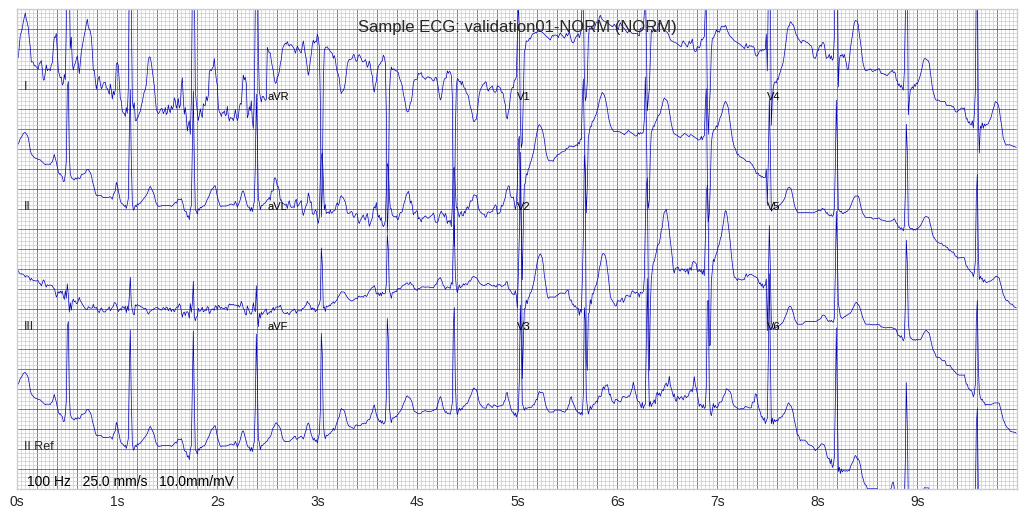

Saved to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/sample_ecg_validation_1.png


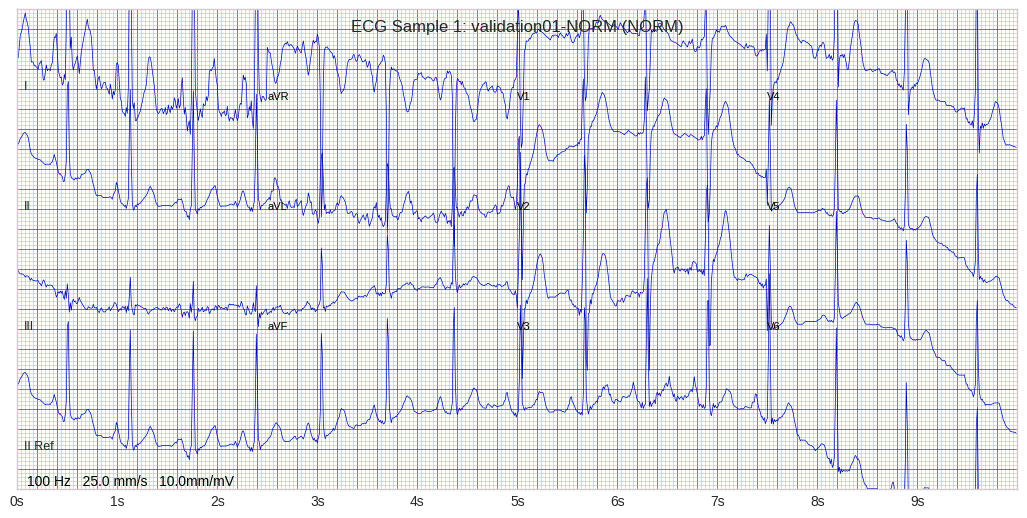

Saved to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/sample_ecg_validation_2.png


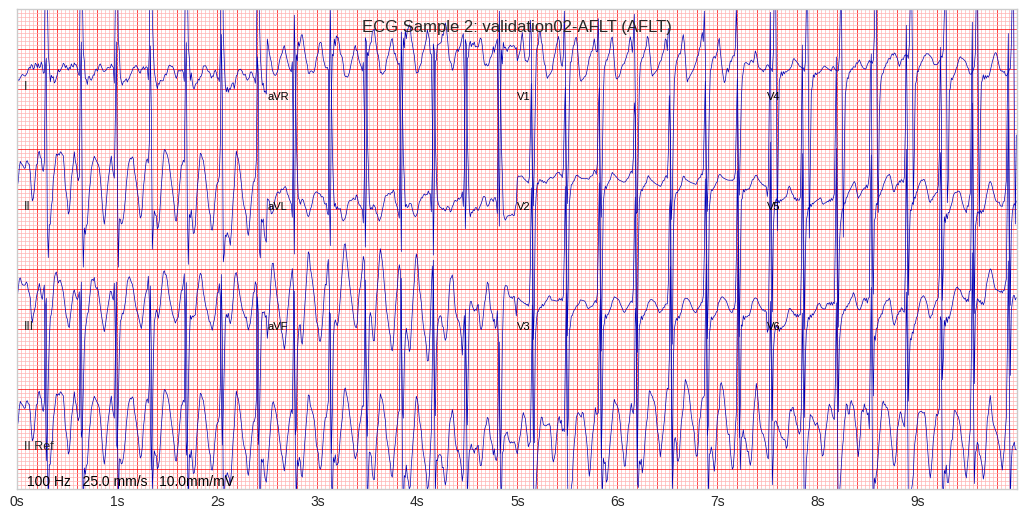

Saved to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/sample_ecg_validation_3.png


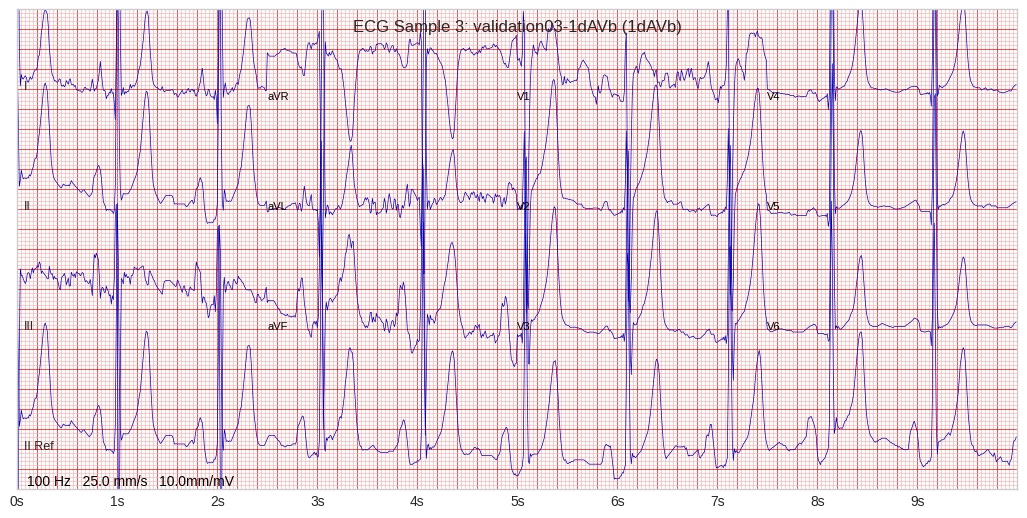

Saved to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/sample_ecg_validation_4.png


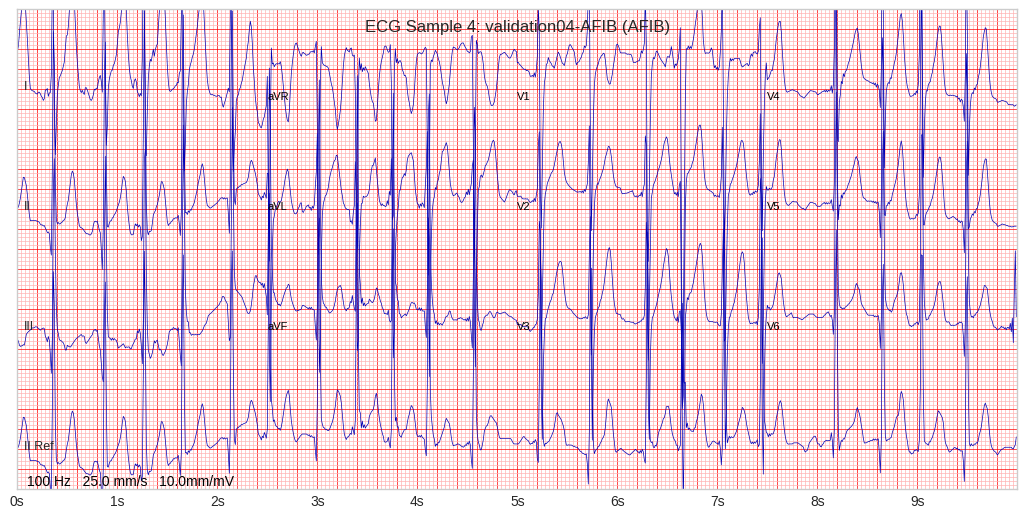

Saved to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/sample_ecg_validation_5.png


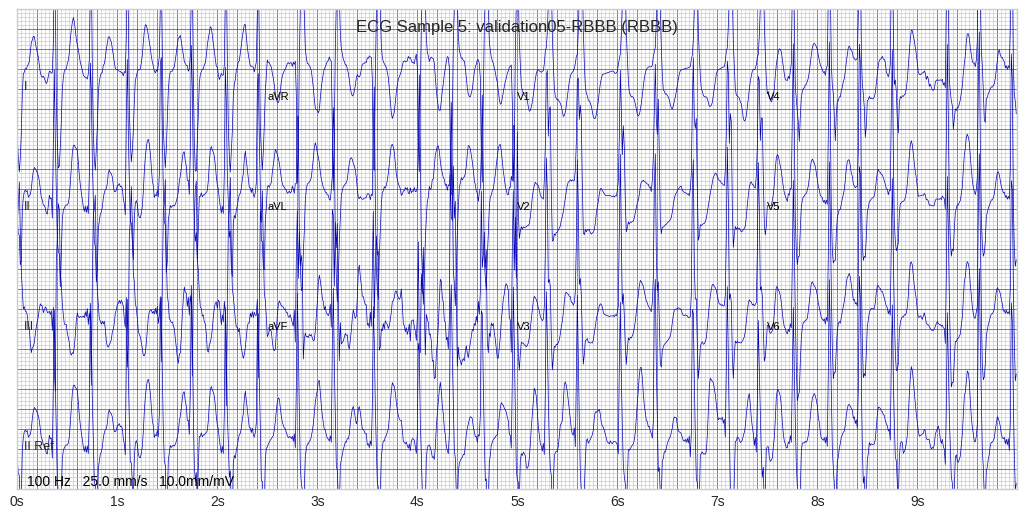

Saved to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/sample_ecg_validation_6.png


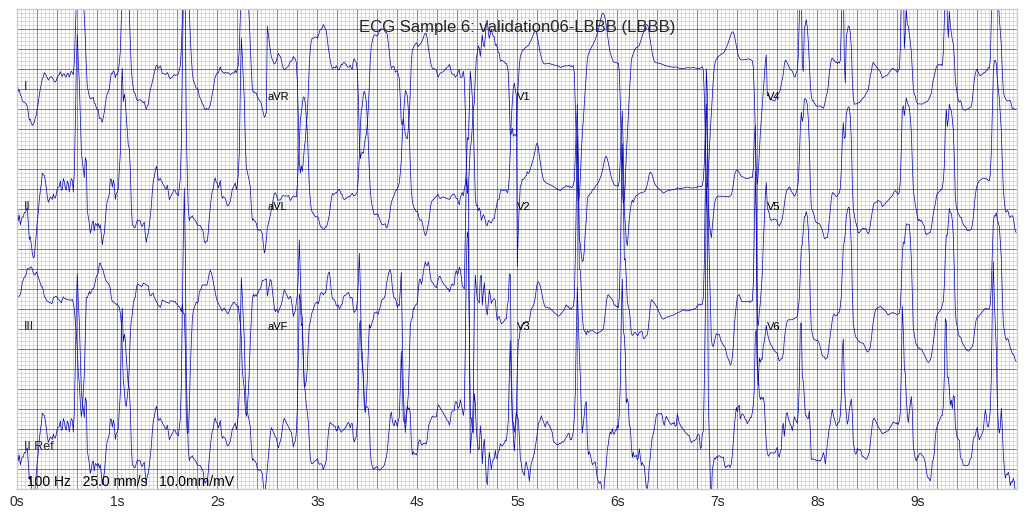

In [11]:
# ============================================
# 4.1 ECG Signal Visualization
# ============================================

def plot_ecg_sample(ecg: np.ndarray, title: str = "ECG Sample", 
                    leads: List[str] = None, save_path: str = None):
    "Plot 12-lead ECG sample in a combined layout similar to plot_ecg_samples.ipynb."
    import ecg_plot
    
    # Ensure ecg is (12, n_samples)
    if ecg.shape[0] != 12 and ecg.shape[1] == 12:
        ecg = ecg.T
    
    sample_rate = 100
    n = ecg.shape[1]
    
    # Quarter marks to split ECG signal into 4 equal time segments
    q1, q2, q3 = n // 4, n // 2, 3 * n // 4
    
    # First row: Lead I, aVR, V1, V4
    lead_I_new = np.concatenate([ecg[0, 0:q1], ecg[3, q1:q2], ecg[6, q2:q3], ecg[9, q3:n]])
    
    # Second row: Lead II, aVL, V2, V5
    lead_II_new = np.concatenate([ecg[1, 0:q1], ecg[4, q1:q2], ecg[7, q2:q3], ecg[10, q3:n]])
    
    # Third row: Lead III, aVF, V3, V6
    lead_III_new = np.concatenate([ecg[2, 0:q1], ecg[5, q1:q2], ecg[8, q2:q3], ecg[11, q3:n]])
    
    # Bottom row (reference): Full Lead II
    lead_IV_new = ecg[1, :]
    
    # Stack the 4 new rows
    ecg_new = np.stack([lead_I_new, lead_II_new, lead_III_new, lead_IV_new], axis=0)
    lead_names_new = ['I', 'II', 'III', 'II Ref']
    
    plt.clf()
    plt.close('all')
    
    ecg_plot.plot(ecg_new, sample_rate=sample_rate, title=title, columns=1, lead_index=lead_names_new)
    
    ax = plt.gca()
    ax.set_yticklabels([])
    
    xlabels = ax.get_xticks()
    new_labels = [f"{int(x)}s" if x % 1 == 0 and x <= 10 else '' for x in xlabels]
    ax.set_xticklabels(new_labels)
    
    ax.text(2.5, -0.75, 'aVR', fontsize=8, color='black')
    ax.text(2.5, -3.5, 'aVL', fontsize=8, color='black')
    ax.text(2.5, -6.5, 'aVF', fontsize=8, color='black')
    
    ax.text(5, -0.75, 'V1', fontsize=8, color='black')
    ax.text(5, -3.5, 'V2', fontsize=8, color='black')
    ax.text(5, -6.5, 'V3', fontsize=8, color='black')
    
    ax.text(7.5, -0.75, 'V4', fontsize=8, color='black')
    ax.text(7.5, -3.5, 'V5', fontsize=8, color='black')
    ax.text(7.5, -6.5, 'V6', fontsize=8, color='black')
    
    ax.text(0.1, -10.4, f'{sample_rate} Hz   25.0 mm/s   10.0mm/mV', fontsize=10, color='black')
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved to {save_path}")
    
    ecg_plot.show()

# Plot sample from validation set
if validation_dataset:
    sample = validation_dataset[0]
    plot_ecg_sample(
        sample['ecg'].numpy(),
        title=f"Sample ECG: {sample['filename']} ({sample['label_str']})",
        save_path=config.output_dir / "sample_ecg_validation.png"
    )

# Plot all validation samples
if validation_dataset:
    for i in range(len(validation_dataset)):
        sample = validation_dataset[i]
        plot_ecg_sample(
            sample['ecg'].numpy(),
            title=f"ECG Sample {i+1}: {sample['filename']} ({sample['label_str']})",
            save_path=config.output_dir / f"sample_ecg_validation_{i+1}.png"
        )

Saved to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/class_distribution_validation.png


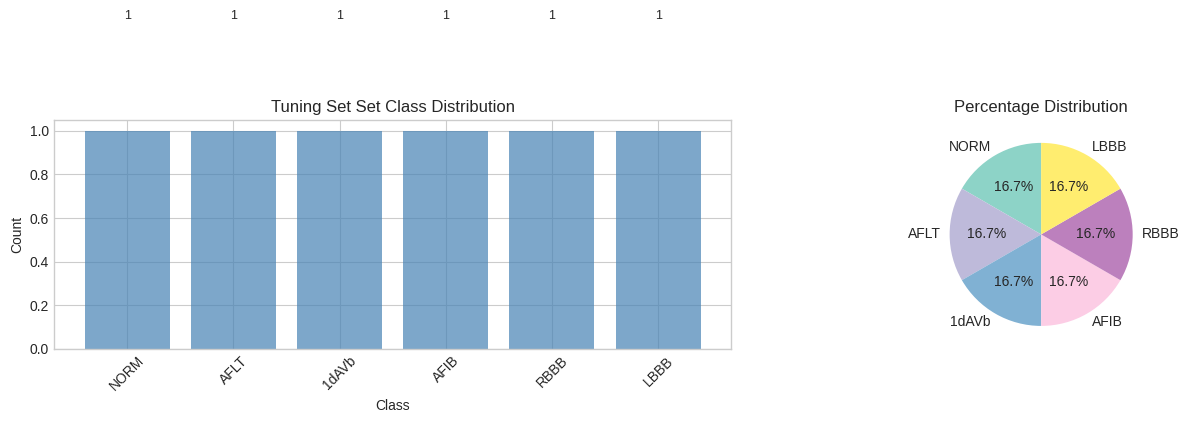

In [12]:
# ============================================
# 4.2 Class Distribution Analysis
# ============================================

def plot_class_distribution(labels: List[str], title: str = "Class Distribution",
                              save_path: str = None):
    "Plot class distribution."
    from collections import Counter
    
    counts = Counter(labels)
    classes = list(counts.keys())
    values = list(counts.values())
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Bar plot
    bars = ax1.bar(classes, values, color='steelblue', alpha=0.7)
    ax1.set_xlabel('Class')
    ax1.set_ylabel('Count')
    ax1.set_title(title)
    ax1.tick_params(axis='x', rotation=45)
    
    # Add count labels on bars
    for bar, val in zip(bars, values):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                str(val), ha='center', va='bottom', fontsize=9)
    
    # Pie chart
    colors = plt.cm.Set3(np.linspace(0, 1, len(classes)))
    wedges, texts, autotexts = ax2.pie(
        values, labels=classes, autopct='%1.1f%%',
        colors=colors, startangle=90
    )
    ax2.set_title('Percentage Distribution')
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved to {save_path}")
    
    plt.show()
    
    return counts

# Plot validation set distribution
if validation_dataset:
    val_counts = plot_class_distribution(
        validation_dataset.labels,
        title="Tuning Set Set Class Distribution",
        save_path=config.output_dir / "class_distribution_validation.png"
    )
    
    # Save to CSV
    class_dist_df = pd.DataFrame([
        {"Class": k, "Count": v} for k, v in val_counts.items()
    ])
    class_dist_df.to_csv(config.output_dir / "class_distribution_validation.csv", index=False)

In [13]:
# ============================================
# 4.3 Signal Statistics
# ============================================

def compute_signal_statistics(dataset: Dataset) -> pd.DataFrame:
    "Compute signal statistics across dataset."
    lead_names = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 
                  'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
    
    all_ecgs = []
    for i in range(len(dataset)):
        sample = dataset[i]
        all_ecgs.append(sample['ecg'].numpy())
    
    all_ecgs = np.array(all_ecgs)  # (N, 12, 1000)
    
    stats = []
    for i, lead in enumerate(lead_names):
        lead_data = all_ecgs[:, i, :].flatten()
        stats.append({
            'Lead': lead,
            'Mean': lead_data.mean(),
            'Std': lead_data.std(),
            'Min': lead_data.min(),
            'Max': lead_data.max(),
            'Median': np.median(lead_data),
            'Range': lead_data.max() - lead_data.min()
        })
    
    return pd.DataFrame(stats)

if validation_dataset:
    signal_stats = compute_signal_statistics(validation_dataset)
    print("Signal Statistics (Validation Set):")
    print(signal_stats.to_string(index=False))
    signal_stats.to_csv(config.output_dir / "signal_statistics.csv", index=False)

Signal Statistics (Validation Set):
Lead          Mean  Std       Min      Max    Median     Range
   I -6.357829e-10  1.0 -2.792752 6.190208 -0.194081  8.982960
  II  4.768371e-09  1.0 -2.982399 6.152369 -0.150017  9.134768
 III -1.112620e-09  1.0 -7.212623 5.666121  0.072890 12.878743
 aVR  9.536744e-10  1.0 -5.706759 2.383577  0.176257  8.090337
 aVL -6.357829e-10  1.0 -5.311388 7.024727 -0.154967 12.336115
 aVF -6.357829e-10  1.0 -5.061748 6.028101 -0.025828 11.089849
  V1  1.430511e-09  1.0 -8.365074 3.304631  0.136027 11.669705
  V2 -9.536744e-10  1.0 -5.485897 3.347370  0.002080  8.833267
  V3 -1.509984e-09  1.0 -5.015229 6.007026 -0.089632 11.022255
  V4  1.351039e-09  1.0 -4.220869 6.322072 -0.134319 10.542940
  V5  2.940496e-09  1.0 -3.498626 6.555541 -0.198139 10.054167
  V6 -5.086263e-09  1.0 -3.107665 6.466437 -0.185907  9.574102


Saved to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/lead_correlation.png


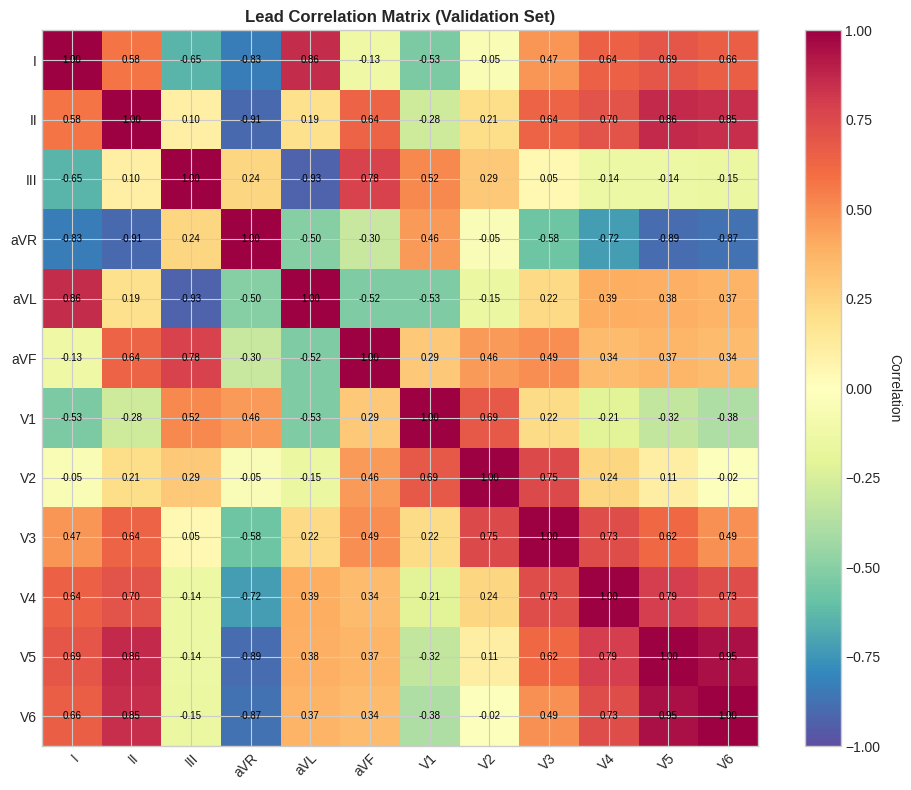

In [14]:
# ============================================
# 4.4 Lead Correlation Analysis
# ============================================

def plot_lead_correlation(dataset: Dataset, title: str = "Lead Correlation Matrix",
                          save_path: str = None):
    "Plot correlation matrix between leads."
    lead_names = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 
                  'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
    
    # Collect all ECGs
    all_ecgs = []
    for i in range(len(dataset)):
        sample = dataset[i]
        all_ecgs.append(sample['ecg'].numpy())
    all_ecgs = np.array(all_ecgs)
    
    # Compute correlation matrix
    # Flatten each lead and compute correlations
    lead_features = all_ecgs.reshape(len(all_ecgs), 12, -1)
    lead_features = lead_features.reshape(len(all_ecgs), 12, -1).mean(axis=2)  # Use mean as feature
    
    # Actually compute correlation on flattened signals
    correlation_matrix = np.zeros((12, 12))
    for i in range(12):
        for j in range(12):
            # Flatten and compute correlation
            lead_i = all_ecgs[:, i, :].flatten()
            lead_j = all_ecgs[:, j, :].flatten()
            correlation_matrix[i, j] = np.corrcoef(lead_i, lead_j)[0, 1]
    
    # Plot
    fig, ax = plt.subplots(figsize=(10, 8))
    im = ax.imshow(correlation_matrix, cmap='Spectral_r', vmin=-1, vmax=1)
    
    # Set ticks
    ax.set_xticks(range(12))
    ax.set_yticks(range(12))
    ax.set_xticklabels(lead_names)
    ax.set_yticklabels(lead_names)
    
    # Rotate x labels
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    
    # Add colorbar
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label('Correlation', rotation=270, labelpad=15)
    
    ax.set_title(title, fontweight='bold')
    
    # Add correlation values
    for i in range(12):
        for j in range(12):
            text = ax.text(j, i, f'{correlation_matrix[i, j]:.2f}',
                          ha="center", va="center", color="black", fontsize=7)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved to {save_path}")
    
    plt.show()

if validation_dataset:
    plot_lead_correlation(
        validation_dataset,
        title="Lead Correlation Matrix (Validation Set)",
        save_path=config.output_dir / "lead_correlation.png"
    )

---

## 5. Model Architectures

This section defines all candidate models including baselines and the final hybrid architecture.

In [15]:
class ConvBlock1D(nn.Module):
    "1D Convolutional block with BatchNorm and ReLU."

    def __init__(self, in_channels, out_channels, kernel_size, stride=1, padding=0, dilation=1, groups=1, bias=False):
        super().__init__()
        self.conv = nn.Conv1d(in_channels, out_channels, kernel_size, stride, padding, dilation, groups, bias)
        self.bn = nn.BatchNorm1d(out_channels)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.relu(self.bn(self.conv(x)))

class ResidualBlock1D(nn.Module):
    "Residual block for 1D signals with optional downsampling and channel change."

    def __init__(self, in_channels, out_channels=None, kernel_size=7, stride=1, dilation=1):
        super().__init__()
        if out_channels is None:
            out_channels = in_channels
            
        padding = (kernel_size - 1) // 2 * dilation
        # Only apply stride to the first convolution
        self.conv1 = ConvBlock1D(in_channels, out_channels, kernel_size, stride, padding, dilation)
        # Second convolution always has stride 1
        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size, 1, padding, dilation)
        self.bn2 = nn.BatchNorm1d(out_channels)
        
        self.downsample = None
        if stride != 1 or in_channels != out_channels:
            self.downsample = nn.Sequential(
                nn.Conv1d(in_channels, out_channels, 1, stride, bias=False),
                nn.BatchNorm1d(out_channels)
            )

    def forward(self, x):
        identity = x
        out = self.conv1(x)
        out = self.conv2(out)
        out = self.bn2(out)
        
        if self.downsample is not None:
            identity = self.downsample(x)
            
        out += identity
        return F.relu(out)

In [16]:
# ============================================
# 5.2 Baseline: 1D CNN
# ============================================

class CNN1D(nn.Module):
    "Simple 1D CNN for ECG classification."
    
    def __init__(self, num_leads=12, num_classes=7, signal_length=1000):
        super().__init__()
        
        # Feature extraction
        self.features = nn.Sequential(
            ConvBlock1D(num_leads, 64, kernel_size=7, stride=2, padding=3),
            nn.MaxPool1d(2),
            ConvBlock1D(64, 128, kernel_size=7, stride=2, padding=3),
            nn.MaxPool1d(2),
            ConvBlock1D(128, 256, kernel_size=5, stride=2, padding=2),
            nn.MaxPool1d(2),
            ConvBlock1D(256, 512, kernel_size=5, stride=1, padding=2),
            nn.AdaptiveAvgPool1d(1)
        )
        
        # Classifier
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(512, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )
    
    def forward(self, x):
        features = self.features(x)
        return self.classifier(features)

print("1D CNN baseline defined.")

1D CNN baseline defined.


In [17]:
class ResNet1D(nn.Module):
    "ResNet-style 1D CNN for ECG classification."

    def __init__(self, num_leads=12, num_classes=7, base_channels=64):
        super().__init__()
        self.stem = nn.Sequential(ConvBlock1D(num_leads, base_channels, kernel_size=7, stride=2, padding=3), nn.MaxPool1d(2))
        self.stage1 = self._make_stage(base_channels, base_channels, 2, stride=1)
        self.stage2 = self._make_stage(base_channels, base_channels * 2, 2, stride=2)
        self.stage3 = self._make_stage(base_channels * 2, base_channels * 4, 2, stride=2)
        self.stage4 = self._make_stage(base_channels * 4, base_channels * 8, 2, stride=2)
        self.head = nn.Sequential(nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Dropout(0.5), nn.Linear(base_channels * 8, num_classes))

    def _make_stage(self, in_channels, out_channels, num_blocks, stride=1):
        layers = []
        layers.append(ResidualBlock1D(in_channels, out_channels, stride=stride))
        for _ in range(1, num_blocks):
            layers.append(ResidualBlock1D(out_channels, out_channels))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)
        return self.head(x)

In [18]:
# ============================================
# 5.4 Baseline: CNN-LSTM
# ============================================

class CNNLSTM(nn.Module):
    "CNN-LSTM hybrid for temporal modeling."
    
    def __init__(self, num_leads=12, num_classes=7, hidden_dim=256,
                 num_layers=2, bidirectional=True):
        super().__init__()
        
        # CNN feature extractor
        self.cnn = nn.Sequential(
            ConvBlock1D(num_leads, 64, kernel_size=7, stride=2, padding=3),
            ConvBlock1D(64, 128, kernel_size=5, stride=2, padding=2),
            ConvBlock1D(128, 256, kernel_size=5, stride=2, padding=2),
        )
        
        # LSTM for temporal dependencies
        self.lstm = nn.LSTM(
            input_size=256,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            bidirectional=bidirectional,
            batch_first=True
        )
        
        lstm_output_dim = hidden_dim * 2 if bidirectional else hidden_dim
        
        # Classifier
        self.classifier = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(lstm_output_dim, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )
    
    def forward(self, x):
        # x: (B, 12, 1000)
        features = self.cnn(x)  # (B, 256, T')
        features = features.permute(0, 2, 1)  # (B, T', 256)
        
        # LSTM
        lstm_out, _ = self.lstm(features)
        lstm_out = lstm_out[:, -1, :]  # Take last output
        
        return self.classifier(lstm_out)

print("CNN-LSTM baseline defined.")

CNN-LSTM baseline defined.


In [19]:
# ============================================
# 5.5 Candidate: Transformer-only
# ============================================

class PatchEmbedding1D(nn.Module):
    "Convert 1D signal to patch embeddings."
    
    def __init__(self, num_leads=12, patch_size=50, embed_dim=256):
        super().__init__()
        self.patch_size = patch_size
        self.num_leads = num_leads
        
        # Project patches to embeddings
        self.proj = nn.Linear(num_leads * patch_size, embed_dim)
        
    def forward(self, x):
        # x: (B, 12, 1000)
        B = x.shape[0]
        
        # Create patches
        num_patches = x.shape[2] // self.patch_size
        x = x[:, :, :num_patches * self.patch_size]
        x = x.reshape(B, self.num_leads, num_patches, self.patch_size)
        x = x.permute(0, 2, 1, 3)  # (B, num_patches, 12, patch_size)
        x = x.reshape(B, num_patches, -1)  # (B, num_patches, 12*patch_size)
        
        return self.proj(x)  # (B, num_patches, embed_dim)


class TransformerEncoder1D(nn.Module):
    "Transformer encoder for 1D signals."
    
    def __init__(self, embed_dim=256, num_heads=8, num_layers=4, dim_ff=1024, dropout=0.1):
        super().__init__()
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=dim_ff,
            dropout=dropout,
            activation='gelu',
            batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers)
    
    def forward(self, x):
        return self.transformer(x)


class TransformerOnly(nn.Module):
    "Pure Transformer model for ECG classification."
    
    def __init__(self, num_leads=12, num_classes=7, patch_size=50,
                 embed_dim=256, num_heads=8, num_layers=4):
        super().__init__()
        
        self.patch_embed = PatchEmbedding1D(num_leads, patch_size, embed_dim)
        num_patches = 1000 // patch_size
        
        # Class token
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        
        # Positional encoding
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches + 1, embed_dim))
        
        # Transformer
        self.transformer = TransformerEncoder1D(embed_dim, num_heads, num_layers)
        
        # Head
        self.head = nn.Sequential(
            nn.LayerNorm(embed_dim),
            nn.Dropout(0.3),
            nn.Linear(embed_dim, num_classes)
        )
        
        self._init_weights()
    
    def _init_weights(self):
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
    
    def forward(self, x):
        B = x.shape[0]
        
        # Patch embedding
        x = self.patch_embed(x)  # (B, num_patches, embed_dim)
        
        # Add class token
        cls_tokens = self.cls_token.expand(B, -1, -1)
        x = torch.cat([cls_tokens, x], dim=1)
        
        # Add positional encoding
        x = x + self.pos_embed
        
        # Transformer
        x = self.transformer(x)
        
        # Use class token for classification
        return self.head(x[:, 0])

print("Transformer-only model defined.")

Transformer-only model defined.


In [20]:
# ============================================
# 5.6 Hybrid CNN-Transformer with ResNet Backbone
# ============================================

class HybridCNNTransformer(nn.Module):
    """
    Hybrid CNN-Transformer architecture with ResNet backbone.
    
    Architecture:
    1. ResNet-style CNN backbone for local feature extraction
    2. Transformer encoder for global context modeling
    3. Gated fusion mechanism
    4. Classification head with confidence estimation
    """
    
    def __init__(self, num_leads=12, num_classes=7, base_channels=64, embed_dim=256, num_heads=8, num_transformer_layers=2, dropout=0.3):
        super().__init__()
        
        # === ResNet Backbone ===
        self.stem = nn.Sequential(
            ConvBlock1D(num_leads, base_channels, kernel_size=7, stride=2, padding=3),
            nn.MaxPool1d(2)
        )
        
        self.stage1 = nn.Sequential(*[ResidualBlock1D(base_channels) for _ in range(2)])
        
        self.stage2 = nn.Sequential(
            ResidualBlock1D(base_channels, base_channels * 2, stride=2),
            ResidualBlock1D(base_channels * 2, base_channels * 2)
        )
        
        self.stage3 = nn.Sequential(
            ResidualBlock1D(base_channels * 2, base_channels * 4, stride=2),
            ResidualBlock1D(base_channels * 4, base_channels * 4)
        )
        
        # Local feature dimension
        self.local_dim = base_channels * 4
        
        # === Transformer Branch ===
        # Create patches from CNN features
        self.patch_size = 25
        self.num_patches = 125 // self.patch_size
        
        # Project patches to embedding dimension
        self.patch_proj = nn.Linear(self.local_dim * self.patch_size, embed_dim)
        
        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=embed_dim * 4,
            dropout=dropout,
            activation='gelu',
            batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_transformer_layers)
        
        # Global pooling
        self.global_pool = nn.AdaptiveAvgPool1d(1)
        
        # === Fusion Mechanism ===
        self.local_fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(self.local_dim, embed_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout)
        )
        
        # Gating network
        self.gate = nn.Sequential(
            nn.Linear(embed_dim * 2, embed_dim),
            nn.Sigmoid()
        )
        
        # === Classification Head ===
        self.classifier = nn.Sequential(
            nn.LayerNorm(embed_dim * 2),
            nn.Dropout(dropout),
            nn.Linear(embed_dim * 2, embed_dim),
            nn.GELU(),
            nn.Dropout(dropout * 0.5),
            nn.Linear(embed_dim, num_classes)
        )
        
        # Temperature scaling for confidence
        self.temperature = nn.Parameter(torch.ones(1) * 1.5)

    def forward(self, x, return_features=False):
        # x: (B, 12, 1000)
        B = x.shape[0]
        
        # === ResNet Backbone (Local Features) ===
        x = self.stem(x)  
        x = self.stage1(x) 
        x = self.stage2(x) 
        cnn_features = self.stage3(x) 
        
        # === Local Feature Path ===
        local_feat = self.global_pool(cnn_features).squeeze(-1) 
        local_feat = self.local_fc(local_feat) 
        
        # === Global Feature Path (Transformer) ===
        # Create patches
        B, C, T = cnn_features.shape
        num_patches = T // self.patch_size
        patches = cnn_features[:, :, :num_patches * self.patch_size] 
        patches = patches.reshape(B, C, num_patches, self.patch_size)
        patches = patches.permute(0, 2, 1, 3) 
        patches = patches.reshape(B, num_patches, -1) 
        
        # Project and apply transformer
        patch_embeds = self.patch_proj(patches) 
        global_feat = self.transformer(patch_embeds) 
        global_feat = global_feat.mean(dim=1) 
        
        # === Gated Fusion ===
        combined = torch.cat([local_feat, global_feat], dim=1) 
        gate_weights = self.gate(combined) 
        
        # Weighted fusion
        local_weighted = local_feat * gate_weights
        global_weighted = global_feat * (1 - gate_weights)
        fused = torch.cat([local_weighted, global_weighted], dim=1)
        
        # === Classification ===
        logits = self.classifier(fused)
        
        # Temperature scaling
        scaled_logits = logits / self.temperature
        
        if return_features:
            return {
                'logits': scaled_logits,
                'local_features': local_feat,
                'global_features': global_feat,
                'gate_weights': gate_weights,
                'cnn_features': cnn_features
            }
        
        return scaled_logits
    
    def predict_with_confidence(self, x, threshold=0.7):
        "Return predictions with confidence scores."
        self.eval()
        with torch.no_grad():
            logits = self.forward(x)
            probs = F.softmax(logits, dim=1)
            max_probs, preds = probs.max(dim=1)
            
            low_confidence = max_probs < threshold
            
            return {
                'predictions': preds,
                'probabilities': probs,
                'max_probabilities': max_probs,
                'low_confidence': low_confidence
            }

print("Hybrid CNN-Transformer with ResNet backbone defined.")

Hybrid CNN-Transformer with ResNet backbone defined.


In [21]:
# ============================================
# 5.7 Model Summary
# ============================================

def count_parameters(model):
    "Count trainable parameters."
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# Initialize models for comparison
models = {
    "CNN1D": CNN1D(),
    "ResNet1D": ResNet1D(),
    "CNN-LSTM": CNNLSTM(),
    "Transformer": TransformerOnly(),
    "Hybrid-CNN-Transformer": HybridCNNTransformer()
}

---

## 6. Training Framework

This section implements the training loop, evaluation metrics, and utilities.

In [22]:
# ============================================
# 6.1 Training Utilities
# ============================================

class EarlyStopping:
    "Early stopping to prevent overfitting."
    
    def __init__(self, patience=10, min_delta=0, mode='min'):
        self.patience = patience
        self.min_delta = min_delta
        self.mode = mode
        self.counter = 0
        self.best_score = None
        self.early_stop = False
    
    def __call__(self, score):
        if self.best_score is None:
            self.best_score = score
        elif self.mode == 'min':
            if score < self.best_score - self.min_delta:
                self.best_score = score
                self.counter = 0
            else:
                self.counter += 1
        else:
            if score > self.best_score + self.min_delta:
                self.best_score = score
                self.counter = 0
            else:
                self.counter += 1
        
        self.early_stop = self.counter >= self.patience
        return self.early_stop


class AverageMeter:
    "Computes and stores the average and current value."
    
    def __init__(self):
        self.reset()
    
    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0
    
    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count


def get_class_weights(labels):
    "Compute class weights for imbalanced data."
    from collections import Counter
    counts = Counter(labels)
    total = sum(counts.values())
    num_classes = len(counts)
    
    # Inverse frequency weighting
    weights = torch.zeros(num_classes)
    for i, class_name in enumerate(config.class_names):
        if class_name in counts:
            weights[i] = total / (num_classes * counts[class_name])
        else:
            weights[i] = 1.0
    
    return weights

print("Training utilities defined.")

Training utilities defined.


In [23]:
# ============================================
# 6.2 Evaluation Metrics
# ============================================

def compute_metrics(y_true, y_pred, y_prob=None):
    """
    Compute comprehensive evaluation metrics.
    
    Args:
        y_true: True labels (np array)
        y_pred: Predicted labels (np array)
        y_prob: Prediction probabilities (np array) - optional for AUROC
    
    Returns:
        Dictionary of metrics
    """
    metrics = {}
    
    # Basic metrics
    metrics['accuracy'] = accuracy_score(y_true, y_pred)
    metrics['precision_macro'] = precision_score(y_true, y_pred, average='macro', zero_division=0)
    metrics['precision_weighted'] = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    metrics['recall_macro'] = recall_score(y_true, y_pred, average='macro', zero_division=0)
    metrics['recall_weighted'] = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    metrics['f1_macro'] = f1_score(y_true, y_pred, average='macro', zero_division=0)
    metrics['f1_weighted'] = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    
    # Per-class metrics
    report = classification_report(y_true, y_pred, labels=range(len(config.class_names)), target_names=config.class_names, output_dict=True, zero_division=0)
    
    for cls in config.class_names:
        if cls in report:
            metrics[f'{cls}_precision'] = report[cls]['precision']
            metrics[f'{cls}_recall'] = report[cls]['recall']
            metrics[f'{cls}_f1'] = report[cls]['f1-score']
            metrics[f'{cls}_support'] = report[cls]['support']
    
    # AUROC and AUPRC (if probabilities provided)
    if y_prob is not None:
        try:
            # One-hot encode for multiclass
            y_true_onehot = np.zeros((len(y_true), len(config.class_names)))
            for i, label in enumerate(y_true):
                y_true_onehot[i, label] = 1
            
            # Macro AUROC
            auroc_scores = []
            for i in range(len(config.class_names)):
                if y_true_onehot[:, i].sum() > 0:  # Only if class exists
                    auroc = roc_auc_score(y_true_onehot[:, i], y_prob[:, i])
                    auroc_scores.append(auroc)
            
            if auroc_scores:
                metrics['auroc_macro'] = np.mean(auroc_scores)
            
            # AUPRC
            auprc_scores = []
            for i in range(len(config.class_names)):
                if y_true_onehot[:, i].sum() > 0:
                    precision, recall, _ = precision_recall_curve(y_true_onehot[:, i], y_prob[:, i])
                    auprc = auc(recall, precision)
                    auprc_scores.append(auprc)
            
            if auprc_scores:
                metrics['auprc_macro'] = np.mean(auprc_scores)
        except Exception as e:
            print(f"Warning: Could not compute AUROC/AUPRC: {e}")
    
    return metrics


def compute_confidence_metrics(probabilities, threshold=0.7):
    """
    Compute confidence-related metrics.
    
    Args:
        probabilities: Prediction probabilities (N, num_classes)
        threshold: Confidence threshold for "low confidence" flag
    
    Returns:
        Dictionary of confidence metrics
    """
    max_probs = probabilities.max(axis=1)
    entropy = -np.sum(probabilities * np.log(probabilities + 1e-10), axis=1)
    
    return {
        'mean_confidence': max_probs.mean(),
        'std_confidence': max_probs.std(),
        'min_confidence': max_probs.min(),
        'median_confidence': np.median(max_probs),
        'low_confidence_ratio': (max_probs < threshold).mean(),
        'mean_entropy': entropy.mean(),
        'high_entropy_ratio': (entropy > 1.0).mean()
    }

print("Evaluation metrics defined.")

Evaluation metrics defined.


In [24]:
# ============================================
# 6.3 Training Loop
# ============================================

def train_epoch(model, dataloader, criterion, optimizer, device, scheduler=None):
    "Train for one epoch."
    model.train()
    
    losses = AverageMeter()
    all_preds = []
    all_labels = []
    all_probs = []
    
    pbar = tqdm(dataloader, desc="Training")
    for batch in pbar:
        ecg = batch['ecg'].to(device)
        labels = batch['label'].reshape(-1).to(device)
        
        optimizer.zero_grad()
        
        outputs = model(ecg)
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        # Track metrics
        losses.update(loss.item(), ecg.size(0))
        
        probs = F.softmax(outputs, dim=1)
        preds = outputs.argmax(dim=1)
        
        all_preds.extend(preds.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())
        all_probs.extend(probs.detach().cpu().numpy())
        
        pbar.set_postfix({'loss': f'{losses.avg:.4f}'})
    
    # Compute metrics
    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)
    
    metrics = compute_metrics(all_labels, all_preds, all_probs)
    metrics['loss'] = losses.avg
    
    return metrics


def validate(model, dataloader, criterion, device):
    "Validate the model."
    model.eval()
    
    losses = AverageMeter()
    all_preds = []
    all_labels = []
    all_probs = []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc="Validation"):
            ecg = batch['ecg'].to(device)
            labels = batch['label'].reshape(-1).to(device)
            
            outputs = model(ecg)
            loss = criterion(outputs, labels)
            
            losses.update(loss.item(), ecg.size(0))
            
            probs = F.softmax(outputs, dim=1)
            preds = outputs.argmax(dim=1)
            
            all_preds.extend(preds.detach().cpu().numpy())
            all_labels.extend(labels.detach().cpu().numpy())
            all_probs.extend(probs.detach().cpu().numpy())
    
    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)
    
    metrics = compute_metrics(all_labels, all_preds, all_probs)
    metrics['loss'] = losses.avg
    metrics['confidence'] = compute_confidence_metrics(all_probs, config.confidence_threshold)
    
    return metrics, all_labels, all_preds, all_probs


def train_model(model, train_loader, val_loader, config, class_weights=None):
    """
    Full training loop with early stopping and learning rate scheduling.
    
    Returns:
        Trained model, training history
    """
    device = torch.device(config.device)
    model = model.to(device)
    
    # Loss function with class weights
    if class_weights is not None:
        class_weights = class_weights.to(device)
        criterion = nn.CrossEntropyLoss(weight=class_weights)
    else:
        criterion = nn.CrossEntropyLoss()
    
    # Optimizer
    optimizer = AdamW(
        model.parameters(),
        lr=config.learning_rate,
        weight_decay=config.weight_decay
    )
    
    # Scheduler
    scheduler = ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=5, 
    )
    
    # Early stopping
    early_stopping = EarlyStopping(
        patience=config.early_stopping_patience, mode='max'
    )
    
    # Training history
    history = {
        'train_loss': [],
        'train_f1': [],
        'val_loss': [],
        'val_f1': [],
        'lr': []
    }
    
    best_model_state = None
    best_f1 = 0.0
    
    print(f"Training on {device}")
    print(f"Epochs: {config.num_epochs}")
    print(f"Batch size: {config.batch_size}")
    print(f"Learning rate: {config.learning_rate}")
    if class_weights is not None:
        print(f"Class weights: {class_weights}")
    print("-" * 60)
    
    for epoch in range(config.num_epochs):
        print(f"Epoch {epoch + 1}/{config.num_epochs}")
        
        # Train
        train_metrics = train_epoch(
            model, train_loader, criterion, optimizer, device
        )
        
        # Validate
        val_metrics, _, _, _ = validate(
            model, val_loader, criterion, device
        )
        
        # Update scheduler
        scheduler.step(val_metrics['loss'])
        
        # Record history
        history['train_loss'].append(train_metrics['loss'])
        history['train_f1'].append(train_metrics['f1_macro'])
        history['val_loss'].append(val_metrics['loss'])
        history['val_f1'].append(val_metrics['f1_macro'])
        history['lr'].append(optimizer.param_groups[0]['lr'])
        
        # Print metrics
        print(f"Train Loss: {train_metrics['loss']:.4f} | F1: {train_metrics['f1_macro']:.4f}")
        print(f"Val Loss: {val_metrics['loss']:.4f} | F1: {val_metrics['f1_macro']:.4f}")
        print(f"LR: {optimizer.param_groups[0]['lr']:.2e}")
        
        # Save best model
        if val_metrics['f1_macro'] > best_f1:
            best_f1 = val_metrics['f1_macro']
            best_model_state = model.state_dict().copy()
            print(f"  ↳ New best F1: {best_f1:.4f}")
        
        # Early stopping
        if early_stopping(val_metrics['f1_macro']):
            print(f"Early stopping at epoch {epoch + 1}")
            break
    
    # Load best model
    if best_model_state is not None:
        model.load_state_dict(best_model_state)
        print(f"Loaded best model with F1: {best_f1:.4f}")
    
    return model, history

print("Training loop defined.")

Training loop defined.


In [25]:
# ============================================
# 6.4 Visualization Functions
# ============================================

def plot_training_history(history, save_path=None):
    "Plot training history."
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    epochs = range(1, len(history['train_loss']) + 1)
    
    # Loss
    axes[0].plot(epochs, history['train_loss'], 'b-', label='Train')
    axes[0].plot(epochs, history['val_loss'], 'r-', label='Val')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Training and Validation Loss')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # F1 Score
    axes[1].plot(epochs, history['train_f1'], 'b-', label='Train')
    axes[1].plot(epochs, history['val_f1'], 'r-', label='Val')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('F1 Score (Macro)')
    axes[1].set_title('Training and Validation F1')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    # Learning Rate
    axes[2].plot(epochs, history['lr'], 'g-')
    axes[2].set_xlabel('Epoch')
    axes[2].set_ylabel('Learning Rate')
    axes[2].set_title('Learning Rate Schedule')
    axes[2].set_yscale('log')
    axes[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved to {save_path}")
    
    plt.show()


def plot_confusion_matrix(y_true, y_pred, class_names, save_path=None):
    "Plot confusion matrix."
    cm = confusion_matrix(y_true, y_pred)
    
    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=class_names, yticklabels=class_names,
        ax=ax, cbar_kws={'label': 'Count'}
    )
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    ax.set_title('Confusion Matrix')
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved to {save_path}")
    
    plt.show()
    
    return cm


def plot_roc_curves(y_true, y_prob, class_names, save_path=None):
    "Plot ROC curves for each class."
    from sklearn.preprocessing import label_binarize
    
    # Binarize labels
    y_true_bin = label_binarize(y_true, classes=range(len(class_names)))
    
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # Plot ROC curve for each class
    for i, class_name in enumerate(class_names):
        if y_true_bin[:, i].sum() > 0:  # Only if class exists
            fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
            roc_auc = auc(fpr, tpr)
            ax.plot(fpr, tpr, label=f'{class_name} (AUC = {roc_auc:.2f})')
    
    # Plot diagonal
    ax.plot([0, 1], [0, 1], 'k--', label='Random')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title('ROC Curves (One-vs-Rest)')
    ax.legend(loc='lower right')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved to {save_path}")
    
    plt.show()

print("Visualization functions defined.")

Visualization functions defined.


---

## 7. Model Training and Benchmarking

This section trains the models and benchmarks them.

In [26]:
# ============================================
# 7.1 Load PTB-XL Training and Validation Data
# ============================================

print("Loading combined PTB-XL and Challenge 2020 datasets...")

# Create PTB-XL datasets
try:
    train_dataset = CombinedECGDataset(
        ptb_xl_dir=config.ptb_xl_dir,
        challenge_2020_dir=config.challenge_2020_dir,
        split='train',
        sampling_rate=config.sampling_rate,
        target_length=config.signal_length,
        normalize=True,
        use_stratified_split=True
    )
    
    val_dataset = CombinedECGDataset(
        ptb_xl_dir=config.ptb_xl_dir,
        challenge_2020_dir=config.challenge_2020_dir,
        split='val',
        sampling_rate=config.sampling_rate,
        target_length=config.signal_length,
        normalize=True,
        use_stratified_split=True
    )
    
    # Create DataLoaders
    train_loader = DataLoader(
        train_dataset,
        batch_size=config.batch_size,
        shuffle=True,
        num_workers=config.num_workers
    )
    
    val_loader = DataLoader(
        val_dataset,
        batch_size=config.batch_size,
        shuffle=False,
        num_workers=config.num_workers
    )
    
    # Compute class weights for training
    class_weights = get_class_weights(train_dataset.labels)
    
    print(f"Successfully loaded combined data:")
    print(f"  Training set: {len(train_dataset)} records")
    print(f"  Validation set: {len(val_dataset)} records")
    print(f"  Class weights: {class_weights.numpy()}")
    
except Exception as e:
    print(f"Error loading PTB-XL dataset: {e}")
    print("Please check if the dataset files exist and are accessible.")

Loading combined PTB-XL and Challenge 2020 datasets...
PTB-XL train set: 17483 records
  Class distribution: {'NORM': 13072, 'AFLT': 624, 'RBBB': 892, '1dAVb': 610, 'OTHERS': 1128, 'LBBB': 62, 'AFIB': 1095}
Combined train set: 17483 PTB-XL = 17483 total
  Combined class distribution: {'NORM': 13072, 'AFLT': 624, 'RBBB': 892, '1dAVb': 610, 'OTHERS': 1128, 'LBBB': 62, 'AFIB': 1095}
PTB-XL val set: 4354 records
  Class distribution: {'NORM': 3255, 'AFLT': 167, '1dAVb': 143, 'AFIB': 285, 'RBBB': 219, 'OTHERS': 270, 'LBBB': 15}
Val set: 4354 PTB-XL records
  Combined class distribution: {'NORM': 3255, 'AFLT': 167, '1dAVb': 143, 'AFIB': 285, 'RBBB': 219, 'OTHERS': 270, 'LBBB': 15}
Successfully loaded combined data:
  Training set: 17483 records
  Validation set: 4354 records
  Class weights: [ 0.19106269  2.2808871   4.002518    4.0943794   2.799968   40.28341
  2.214159  ]


In [27]:
# ============================================
# 7.2 Benchmark Baseline Models (Loading Pre-trained)
# ============================================

from ecg_module import DeepECGSSL

class BioMedClipSignalAdapter(nn.Module):
    """
    Adapter to project 1D ECG signals [B, 12, 1000] to 2D image format [B, 3, 224, 224]
    expected by the BioMedClip model.
    """
    def __init__(self, traced_model):
        super().__init__()
        self.model = traced_model
        
    def forward(self, x):
        # x: [B, 12, 1000]
        # Interpolate 1D signal to match 4D image dimensions [B, 3, 224, 224]
        B = x.shape[0]
        x_resized = torch.nn.functional.interpolate(x.unsqueeze(1), size=(224, 224), mode='bilinear', align_corners=False) # [B, 1, 224, 224]
        x_resized = x_resized.repeat(1, 3, 1, 1) # [B, 3, 224, 224]
        
        # Normalize using classes.json mean/std
        mean = torch.tensor([0.48145466, 0.4578275, 0.40821073], device=x.device).view(1, 3, 1, 1)
        std = torch.tensor([0.26862954, 0.26130258, 0.27577711], device=x.device).view(1, 3, 1, 1)
        x_normalized = (x_resized - mean) / std
        return self.model(x_normalized)

def load_and_benchmark_model(model_class, model_name, model_path, val_loader, config, model_kwargs=None):
    """
    Load a pre-trained model and benchmark it.
    """
    print(f"{'='*60}")
    print(f"Loading and Evaluating: {model_name}")
    print(f"Path: {model_path}")
    print(f"{'='*60}")
    
    if model_kwargs is None:
        model_kwargs = {}
        
    device = torch.device(config.device)
    
    # Check if this is a traced TorchScript model
    if model_path.endswith('.pt'):
        try:
            if not os.path.exists(model_path):
                 print(f"Warning: {model_path} does not exist.")
                 return None
                 
            # HubertECG is baked/compiled for CUDA and will fail on CPU
            if model_name == "HubertECG" and device.type == 'cpu':
                 print(f"Warning: {model_name} is traced/locked to CUDA and cannot run on CPU. Skipping.")
                 return None
                 
            model = torch.jit.load(model_path, map_location=device)
            print(f"Successfully loaded traced model {model_name} from {model_path}")
            
            # Wrap BioMedClip with the 1D signal to 2D image adapter
            if model_name == "BioMedClip":
                model = BioMedClipSignalAdapter(model)
                print(f"Wrapped {model_name} with BioMedClipSignalAdapter")
        except Exception as e:
            print(f"Error loading traced model {model_name}: {e}")
            return None
    else:
        # Initialize model with specific kwargs if provided
        model = model_class(**model_kwargs)
        
        # Load weights
        try:
            if not os.path.exists(model_path):
                 print(f"Warning: {model_path} does not exist.")
                 return None
                 
            checkpoint = torch.load(model_path, map_location=device)
            
            # Handle cases where state_dict is nested
            if (isinstance(checkpoint, dict) or hasattr(checkpoint, 'keys')) and 'model_state_dict' in checkpoint:
                state_dict = checkpoint['model_state_dict']
                print(f"Extracted 'model_state_dict' from checkpoint.")
            else:
                state_dict = checkpoint
                
            model.load_state_dict(state_dict)
            print(f"Successfully loaded {model_name} from {model_path}")
        except Exception as e:
            print(f"Error loading {model_name}: {e}")
            return None
            
    model.to(device)
    
    # Evaluate
    try:
        metrics, y_true, y_pred, y_prob = validate(
            model, val_loader, nn.CrossEntropyLoss(), device
        )
    except Exception as e:
        print(f"Error evaluating {model_name}: {e}")
        return {
            'history': None,
            'metrics': None,
            'model': model
        }
    
    return {
        'history': None, # No history when loading
        'metrics': metrics,
        'model': model
    }

# Run benchmarks
benchmark_results = {}

# Specific hyperparameters derived from the checkpoint mismatches
models_to_load = [
    (CNN1D, "CNN1D", "output/training-22May/best_model_cnn1d.pth", {}),
    (ResNet1D, "ResNet1D", "output/training-22May/best_model_resnet1d.pth", {'base_channels': 64}),
    (CNNLSTM, "CNN-LSTM", "output/training-22May/best_model_cnnlstm.pth", {'hidden_dim': 128, 'num_layers': 2}),
    (TransformerOnly, "Transformer", "output/training-22May/best_model_transformeronly.pth", {'embed_dim': 128, 'num_heads': 4, 'num_layers': 4}),
    (DeepECGSSL, "DeepECGSSL", "output/training-22May/best_model_deepecgssl.pth", {'embed_dim': 128, 'num_heads': 4, 'num_layers': 3}),
    (None, "BioMedClip", "output/training-22May/biomedclip_traced.pt", {}),
    (None, "HubertECG", "output/training-22May/hubert_ecg_traced.pt", {}),
    (None, "Xresnet1d101", "output/training-22May/xresnet1d101_traced.pt", {}),
]

for model_class, model_name, model_path, kwargs in models_to_load:
    result = load_and_benchmark_model(
        model_class, model_name, model_path, val_loader, config, model_kwargs=kwargs
    )
    if result:
        benchmark_results[model_name] = result

print("Baseline models loaded and evaluated.")

Loading and Evaluating: CNN1D
Path: output/training-22May/best_model_cnn1d.pth
Extracted 'model_state_dict' from checkpoint.
Successfully loaded CNN1D from output/training-22May/best_model_cnn1d.pth


Validation: 100%|██████████| 137/137 [00:21<00:00,  6.45it/s]


Loading and Evaluating: ResNet1D
Path: output/training-22May/best_model_resnet1d.pth
Extracted 'model_state_dict' from checkpoint.
Successfully loaded ResNet1D from output/training-22May/best_model_resnet1d.pth


Validation: 100%|██████████| 137/137 [00:23<00:00,  5.80it/s]


Loading and Evaluating: CNN-LSTM
Path: output/training-22May/best_model_cnnlstm.pth
Extracted 'model_state_dict' from checkpoint.
Successfully loaded CNN-LSTM from output/training-22May/best_model_cnnlstm.pth


Validation: 100%|██████████| 137/137 [00:21<00:00,  6.34it/s]


... (7 outputs left out)

Validation: 100%|██████████| 137/137 [00:34<00:00,  3.92it/s]


Loading and Evaluating: Xresnet1d101
Path: output/training-22May/xresnet1d101_traced.pt
Successfully loaded traced model Xresnet1d101 from output/training-22May/xresnet1d101_traced.pt


Validation: 100%|██████████| 137/137 [00:35<00:00,  3.90it/s]

Baseline models loaded and evaluated.


In [28]:
# ============================================
# 7.2.1 External Validation (Baseline Models)
# ============================================
external_validation_results = {}

# Setup device
device = torch.device(config.device)

if 'validation_loader' in locals() and validation_loader is not None:
    print("Evaluating Baseline Models on External Validation Set:")
    for model_name, result in benchmark_results.items():
        if result.get('metrics') is None:
            print(f"Skipping {model_name} as it has no valid baseline metrics.")
            continue
        model = result['model']
        try:
            metrics, y_true, y_pred, y_prob = validate(
                model, validation_loader, nn.CrossEntropyLoss(), device
            )
            external_validation_results[model_name] = {
                'metrics': metrics,
                'model': model
            }
            print(f"{model_name}: Accuracy = {metrics['accuracy']:.4f}, F1 (Macro) = {metrics['f1_macro']:.4f}")
        except Exception as e:
            print(f"Error evaluating {model_name} on external validation set: {e}")
else:
    print("validation_loader is not defined. Cannot run external validation.")


Evaluating Baseline Models on External Validation Set:


Validation: 100%|██████████| 6/6 [00:00<00:00, 23.17it/s]


CNN1D: Accuracy = 0.5000, F1 (Macro) = 0.4000


Validation: 100%|██████████| 6/6 [00:00<00:00, 19.87it/s]


ResNet1D: Accuracy = 0.6667, F1 (Macro) = 0.5556


Validation: 100%|██████████| 6/6 [00:00<00:00, 20.97it/s]


... (7 outputs left out)

Validation: 100%|██████████| 6/6 [00:00<00:00, 14.87it/s]


HubertECG: Accuracy = 0.5000, F1 (Macro) = 0.4167


Validation: 100%|██████████| 6/6 [00:27<00:00,  4.53s/it]

Xresnet1d101: Accuracy = 1.0000, F1 (Macro) = 1.0000


In [29]:
# ============================================
# 7.3 Load Final Hybrid Model
# ============================================

print("="*60)
print("Loading Final Hybrid CNN-Transformer Model")
print("="*60)

final_model_path = "output/training-22May/best_model_hybridcnntransformer.pth"

# Using derived hyperparameters for the Hybrid model as well
final_model = HybridCNNTransformer(
    base_channels=64,
    embed_dim=256,
    num_heads=4,
    num_transformer_layers=1,
    dropout=0.12
)

device = torch.device(config.device)
try:
    if os.path.exists(final_model_path):
        checkpoint = torch.load(final_model_path, map_location=device)
        
        # Handle cases where state_dict is nested
        if (isinstance(checkpoint, dict) or hasattr(checkpoint, 'keys')) and 'model_state_dict' in checkpoint:
            state_dict = checkpoint['model_state_dict']
        else:
            state_dict = checkpoint
            
        final_model.load_state_dict(state_dict)
        final_model.to(device)
        print(f"Successfully loaded Final Hybrid Model from {final_model_path}")
        
        # Evaluate and add to benchmark results
        metrics, y_true, y_pred, y_prob = validate(
            final_model, val_loader, nn.CrossEntropyLoss(), device
        )
        
        benchmark_results["Hybrid CNN-Transformer"] = {
            'history': None,
            'metrics': metrics,
            'model': final_model
        }
    else:
        print(f"Warning: {final_model_path} does not exist.")
    
except Exception as e:
    print(f"Error loading Final Hybrid Model: {e}")

# Save model architecture summary
model_info = {
    "architecture": "Hybrid CNN-Transformer with ResNet Backbone",
    "parameters": count_parameters(final_model),
    "num_classes": config.num_classes,
    "input_shape": (12, 1000),
    "class_names": config.class_names
}

with open(config.output_dir / "model_info.json", 'w') as f:
    json.dump(model_info, f, indent=2)

print(f"Model Info:")
for k, v in model_info.items():
    print(f"  {k}: {v}")

Loading Final Hybrid CNN-Transformer Model
Successfully loaded Final Hybrid Model from output/training-22May/best_model_hybridcnntransformer.pth


Validation: 100%|██████████| 137/137 [00:20<00:00,  6.84it/s]

Model Info:
  architecture: Hybrid CNN-Transformer with ResNet Backbone
  parameters: 4933128
  num_classes: 7
  input_shape: (12, 1000)
  class_names: ['NORM', 'AFIB', 'AFLT', '1dAVb', 'RBBB', 'LBBB', 'OTHERS']


In [30]:
# ============================================
# 7.3.1 External Validation (Final Hybrid Model)
# ============================================
# Setup device
device = torch.device(config.device)

if 'validation_loader' in locals() and validation_loader is not None and 'final_model' in locals():
    print("Evaluating Final Hybrid Model on External Validation Set:")
    try:
        final_model.to(device)
        metrics, y_true, y_pred, y_prob = validate(
            final_model, validation_loader, nn.CrossEntropyLoss(), device
        )
        external_validation_results["Hybrid CNN-Transformer"] = {
            'metrics': metrics,
            'model': final_model
        }
        print(f"Hybrid CNN-Transformer: Accuracy = {metrics['accuracy']:.4f}, F1 (Macro) = {metrics['f1_macro']:.4f}")
    except Exception as e:
        print(f"Error evaluating Final Hybrid Model on external validation set: {e}")
else:
    print("validation_loader or final_model is not defined. Cannot run external validation.")


Evaluating Final Hybrid Model on External Validation Set:


Validation: 100%|██████████| 6/6 [00:00<00:00, 19.80it/s]

Hybrid CNN-Transformer: Accuracy = 0.5000, F1 (Macro) = 0.3810


In [31]:
# ============================================
# 7.4 Benchmark Results Table
# ============================================

def create_benchmark_table(results_dict, save_path=None):
    """
    Create benchmark results table.
    """
    if not results_dict:
        # Create empty template
        df = pd.DataFrame(columns=[
            'Model', 'Accuracy', 'Precision (Macro)', 'Recall (Macro)',
            'F1 (Macro)', 'AUROC (Macro)', 'Parameters'
        ])
        print("No benchmark results yet. Load models first.")
        return df
    
    data = []
    for model_name, result in results_dict.items():
        metrics = result['metrics']
        if metrics is None:
            continue
        data.append({
            'Model': model_name,
            'Accuracy': metrics.get('accuracy', 0),
            'Precision (Macro)': metrics.get('precision_macro', 0),
            'Recall (Macro)': metrics.get('recall_macro', 0),
            'F1 (Macro)': metrics.get('f1_macro', 0),
            'AUROC (Macro)': metrics.get('auroc_macro', 0),
            'Parameters': count_parameters(result['model'])
        })
    
    df = pd.DataFrame(data)
    df = df.sort_values('F1 (Macro)', ascending=False)
    
    if save_path:
        df.to_csv(save_path, index=False)
        print(f"Saved to {save_path}")
    
    return df

# Create benchmark table
benchmark_df = create_benchmark_table(
    benchmark_results, 
    config.output_dir / "benchmark_results.csv"
)

if not benchmark_df.empty:
    print("Benchmark Results (All 5 Models):")
    print(benchmark_df.to_string(index=False))
else:
    print("No benchmark results available.")

Saved to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/benchmark_results.csv
Benchmark Results (All 5 Models):
                 Model  Accuracy  Precision (Macro)  Recall (Macro)  F1 (Macro)  AUROC (Macro)  Parameters
              ResNet1D  0.942582           0.850326        0.806131    0.826431       0.973693     8736775
              CNN-LSTM  0.918695           0.796223        0.769433    0.780891       0.962244     1035399
Hybrid CNN-Transformer  0.896187           0.731352        0.733809    0.727674       0.949163     4933128
            DeepECGSSL  0.659623           0.626624        0.585438    0.536395       0.925358     1841671
                 CNN1D  0.471750           0.439701        0.480345    0.392885       0.810744     1016967
             HubertECG  0.515847           0.349895        0.445082    0.330571       0.781363    93129095
           Transformer  0.267340           0.419885        0.404505    0.322993       0.780424     1400327
          Xresnet1d10

In [32]:
# ============================================
# 7.4.1 External Validation Benchmark Results
# ============================================

ext_benchmark_df = create_benchmark_table(
    external_validation_results, 
    config.output_dir / "external_benchmark_results.csv"
)

if not ext_benchmark_df.empty:
    print("External Validation Benchmark Results (All Models):")
    print(ext_benchmark_df.to_string(index=False))
else:
    print("No external benchmark results available.")

Saved to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/external_benchmark_results.csv
External Validation Benchmark Results (All Models):
                 Model  Accuracy  Precision (Macro)  Recall (Macro)  F1 (Macro)  AUROC (Macro)  Parameters
          Xresnet1d101  1.000000           1.000000        1.000000    1.000000       1.000000     1809287
              CNN-LSTM  0.666667           0.583333        0.666667    0.611111       0.833333     1035399
              ResNet1D  0.666667           0.500000        0.666667    0.555556       0.900000     8736775
             HubertECG  0.500000           0.388889        0.500000    0.416667       0.800000    93129095
                 CNN1D  0.500000           0.375000        0.500000    0.400000       0.633333     1016967
Hybrid CNN-Transformer  0.500000           0.357143        0.428571    0.380952       0.900000     4933128
            DeepECGSSL  0.333333           0.142857        0.285714    0.190476       0.833333     18

In [33]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
from tqdm import tqdm

# =====================================================================
# GENERATING VALIDATION PREDICTIONS FOR ALL MODELS
# =====================================================================
print("Generating predictions for all models on internal and external validation sets...")

models_to_predict = [
    'BioMedClip', 'CNN1D', 'CNN-LSTM', 'DeepECGSSL',
    'HubertECG', 'Hybrid CNN-Transformer', 'ResNet1D', 'Transformer', 'Xresnet1d101'
]

def predict_dataset(model, loader, model_name, device, threshold=0.7, class_names=None):
    if class_names is None:
        class_names = config.class_names
    model.eval()
    predictions = []
    
    with torch.no_grad():
        for batch in tqdm(loader, desc=f"Predicting {model_name}"):
            ecgs = batch['ecg'].to(device)
            
            # Extract filenames/ids
            filenames = batch.get('filename')
            if filenames is None:
                if 'record_id' in batch:
                    filenames = batch['record_id']
                elif 'record_idx' in batch:
                    filenames = [f"record_{idx.item()}" for idx in batch['record_idx']]
                else:
                    filenames = ['unknown'] * ecgs.size(0)
            
            # Handle list vs string
            if isinstance(filenames, str):
                filenames = [filenames]
            elif not isinstance(filenames, (list, tuple)):
                filenames = list(filenames)
                
            outputs = model(ecgs)
            probs = F.softmax(outputs, dim=1)
            
            max_probs, preds = probs.max(dim=1)
            top3_probs, top3_indices = probs.topk(3, dim=1)
            
            for b_idx in range(ecgs.size(0)):
                fn = filenames[b_idx] if b_idx < len(filenames) else 'unknown'
                pred_val = preds[b_idx].item()
                max_p = max_probs[b_idx].item()
                
                pred_data = {
                    'model': model_name,
                    'filename': fn,
                    'predicted_class': class_names[pred_val],
                    'confidence': max_p,
                    'low_confidence_flag': max_p < threshold
                }
                for (i, cls) in enumerate(class_names):
                    pred_data[f'prob_{cls}'] = probs[b_idx, i].item()
                
                pred_data['top2_class'] = class_names[top3_indices[b_idx, 1].item()]
                pred_data['top2_confidence'] = top3_probs[b_idx, 1].item()
                pred_data['top3_class'] = class_names[top3_indices[b_idx, 2].item()]
                pred_data['top3_confidence'] = top3_probs[b_idx, 2].item()
                
                predictions.append(pred_data)
    return predictions

all_external_preds = []
all_internal_preds = []
device = torch.device(config.device)

for model_name in models_to_predict:
    # Retrieve model
    model = None
    if 'benchmark_results' in locals() and model_name in benchmark_results:
        model = benchmark_results[model_name].get('model')
    elif 'benchmark_results' in locals() and model_name == 'CNN-LSTM' and 'CNN_LSTM' in benchmark_results:
        model = benchmark_results['CNN_LSTM'].get('model')
    else:
        # Fallback check for direct local variables
        local_var_name = model_name.replace(' ', '_').replace('-', '_')
        if model_name in locals():
            model = locals()[model_name]
        elif f"{local_var_name}_model" in locals():
            model = locals()[f"{local_var_name}_model"]
        elif model_name == 'Hybrid CNN-Transformer' and 'final_model' in locals():
            model = final_model
            
    if model is not None:
        print(f"\nProcessing {model_name}...")
        # 1. External validation predictions
        if 'validation_loader' in locals() and validation_loader is not None:
            ext_preds = predict_dataset(model, validation_loader, model_name, device, config.confidence_threshold)
            all_external_preds.extend(ext_preds)
        else:
            print("  Warning: validation_loader (external) is not available.")
        
        # 2. Internal validation predictions
        if 'val_loader' in locals() and val_loader is not None:
            int_preds = predict_dataset(model, val_loader, model_name, device, config.confidence_threshold)
            all_internal_preds.extend(int_preds)
        else:
            print("  Warning: val_loader (internal) is not available.")
    else:
        print(f"\nWarning: Model '{model_name}' not loaded in current environment. Skipping.")

# Save external validation predictions
if all_external_preds:
    df_ext = pd.DataFrame(all_external_preds)
    df_ext.sort_values(['model', 'filename'], inplace=True, ignore_index=True)
    ext_path = config.output_dir / "all_external_val_predictions.csv"
    df_ext.to_csv(ext_path, index=False)
    print(f"\nSaved all external validation predictions to {ext_path} (shape: {df_ext.shape})")

# Save internal validation predictions
if all_internal_preds:
    df_int = pd.DataFrame(all_internal_preds)
    df_int.sort_values(['model', 'filename'], inplace=True, ignore_index=True)
    int_path = config.output_dir / "all_internal_val_predictions.csv"
    df_int.to_csv(int_path, index=False)
    print(f"Saved all internal validation predictions to {int_path} (shape: {df_int.shape})")

Generating predictions for all models on internal and external validation sets...

Processing BioMedClip...


Predicting BioMedClip: 100%|██████████| 137/137 [02:59<00:00,  1.31s/it]



Processing CNN1D...


Predicting CNN1D: 100%|██████████| 137/137 [00:15<00:00,  8.69it/s]



Processing CNN-LSTM...


Predicting CNN-LSTM: 100%|██████████| 137/137 [00:18<00:00,  7.33it/s]


... (9 outputs left out)

Predicting Transformer: 100%|██████████| 137/137 [00:16<00:00,  8.14it/s]



Processing Xresnet1d101...


Predicting Xresnet1d101: 100%|██████████| 137/137 [00:21<00:00,  6.48it/s]



Saved all external validation predictions to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/all_external_val_predictions.csv (shape: (54, 16))
Saved all internal validation predictions to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/all_internal_val_predictions.csv (shape: (39186, 16))


---

## 8. Test Set Predictions

This section generates predictions for the assignment test set.

In [34]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
from tqdm import tqdm

# =====================================================================
# GENERATING TEST PREDICTIONS FOR ALL MODELS
# =====================================================================
print("Generating predictions for all models on test set...")

models_to_predict = [
    'BioMedClip', 'CNN1D', 'CNN-LSTM', 'DeepECGSSL',
    'HubertECG', 'Hybrid CNN-Transformer', 'ResNet1D', 'Transformer', 'Xresnet1d101'
]

def predict_dataset(model, loader, model_name, device, threshold=0.7, class_names=None):
    if class_names is None:
        class_names = config.class_names
    model.eval()
    predictions = []
    
    with torch.no_grad():
        for batch in tqdm(loader, desc=f"Predicting {model_name}"):
            ecgs = batch['ecg'].to(device)
            
            # Extract filenames/ids
            filenames = batch.get('filename')
            if filenames is None:
                if 'record_id' in batch:
                    filenames = batch['record_id']
                elif 'record_idx' in batch:
                    filenames = [f"record_{idx.item()}" for idx in batch['record_idx']]
                else:
                    filenames = ['unknown'] * ecgs.size(0)
            
            # Handle list vs string
            if isinstance(filenames, str):
                filenames = [filenames]
            elif not isinstance(filenames, (list, tuple)):
                filenames = list(filenames)
                
            outputs = model(ecgs)
            probs = F.softmax(outputs, dim=1)
            
            max_probs, preds = probs.max(dim=1)
            top3_probs, top3_indices = probs.topk(3, dim=1)
            
            for b_idx in range(ecgs.size(0)):
                fn = filenames[b_idx] if b_idx < len(filenames) else 'unknown'
                pred_val = preds[b_idx].item()
                max_p = max_probs[b_idx].item()
                
                pred_data = {
                    'model': model_name,
                    'filename': fn,
                    'predicted_class': class_names[pred_val],
                    'confidence': max_p,
                    'low_confidence_flag': max_p < threshold
                }
                for (i, cls) in enumerate(class_names):
                    pred_data[f'prob_{cls}'] = probs[b_idx, i].item()
                
                pred_data['top2_class'] = class_names[top3_indices[b_idx, 1].item()]
                pred_data['top2_confidence'] = top3_probs[b_idx, 1].item()
                pred_data['top3_class'] = class_names[top3_indices[b_idx, 2].item()]
                pred_data['top3_confidence'] = top3_probs[b_idx, 2].item()
                
                predictions.append(pred_data)
    return predictions

all_test_preds = []
device = torch.device(config.device)

for model_name in models_to_predict:
    # Retrieve model
    model = None
    if 'benchmark_results' in locals() and model_name in benchmark_results:
        model = benchmark_results[model_name].get('model')
    elif 'benchmark_results' in locals() and model_name == 'CNN-LSTM' and 'CNN_LSTM' in benchmark_results:
        model = benchmark_results['CNN_LSTM'].get('model')
    else:
        # Fallback check for direct local variables
        local_var_name = model_name.replace(' ', '_').replace('-', '_')
        if model_name in locals():
            model = locals()[model_name]
        elif f"{local_var_name}_model" in locals():
            model = locals()[f"{local_var_name}_model"]
        elif model_name == 'Hybrid CNN-Transformer' and 'final_model' in locals():
            model = final_model
            
    if model is not None:
        print(f"\nProcessing {model_name}...")
        if 'test_loader' in locals() and test_loader is not None:
            test_preds = predict_dataset(model, test_loader, model_name, device, config.confidence_threshold)
            all_test_preds.extend(test_preds)
        else:
            print("  Warning: test_loader is not available.")
    else:
        print(f"\nWarning: Model '{model_name}' not loaded in current environment. Skipping.")

# Save test predictions
if all_test_preds:
    df_test = pd.DataFrame(all_test_preds)
    df_test.sort_values(['model', 'filename'], inplace=True, ignore_index=True)
    test_path = config.output_dir / "all_test_predictions.csv"
    df_test.to_csv(test_path, index=False)
    print(f"\nSaved all test predictions to {test_path} (shape: {df_test.shape})")

Generating predictions for all models on test set...

Processing BioMedClip...


Predicting BioMedClip: 100%|██████████| 6/6 [00:00<00:00, 12.04it/s]



Processing CNN1D...


Predicting CNN1D: 100%|██████████| 6/6 [00:00<00:00, 48.99it/s]



Processing CNN-LSTM...


Predicting CNN-LSTM: 100%|██████████| 6/6 [00:00<00:00, 42.89it/s]


... (9 outputs left out)

Predicting Transformer: 100%|██████████| 6/6 [00:00<00:00, 45.53it/s]



Processing Xresnet1d101...


Predicting Xresnet1d101: 100%|██████████| 6/6 [00:00<00:00, 42.44it/s]


Saved all test predictions to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/all_test_predictions.csv (shape: (54, 16))


---

## 9. Model Explainability

This section generates explainability of the best performing model on the external validation dataset.

Generating and plotting 6 validation samples with NeuroKit2 wave peaks...
Saved figure with PQRST delineation to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/sample_ecg_validation_1.png


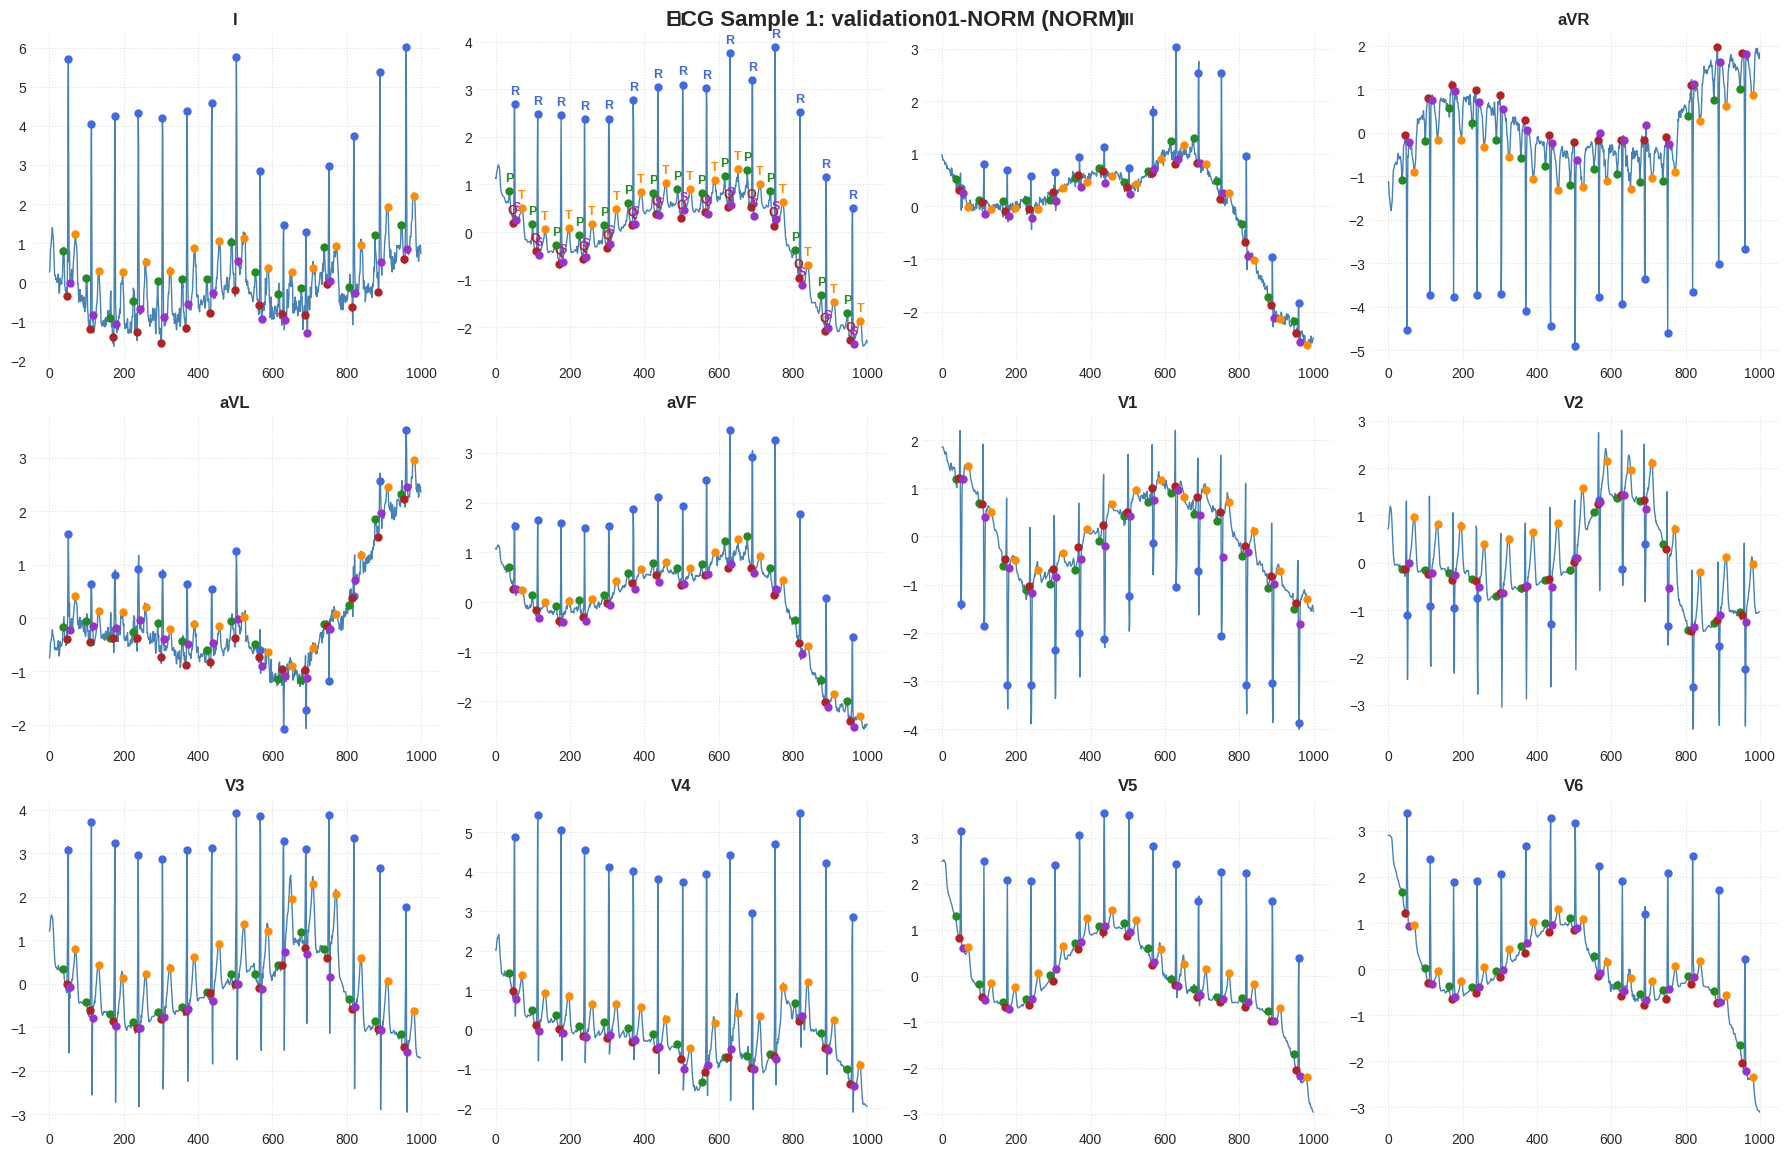

Saved figure with PQRST delineation to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/sample_ecg_validation_2.png


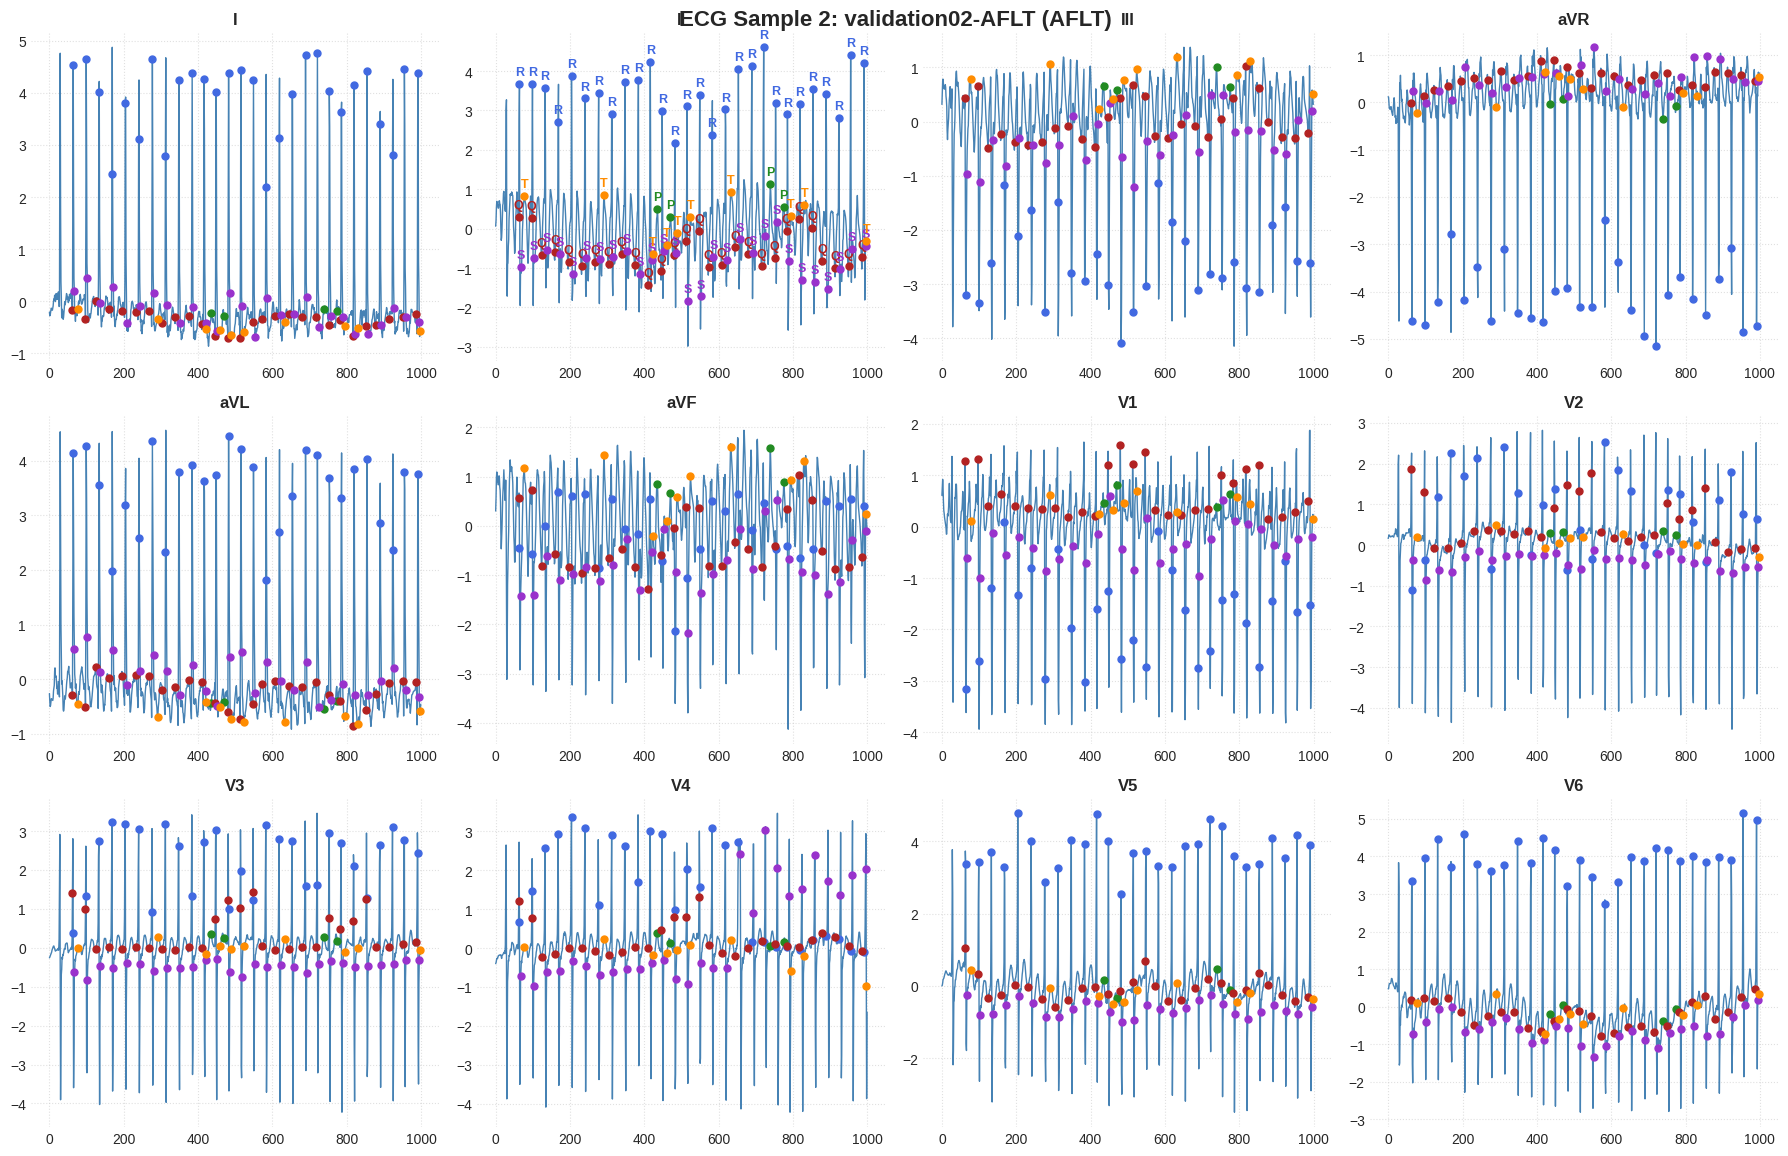

Saved figure with PQRST delineation to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/sample_ecg_validation_3.png


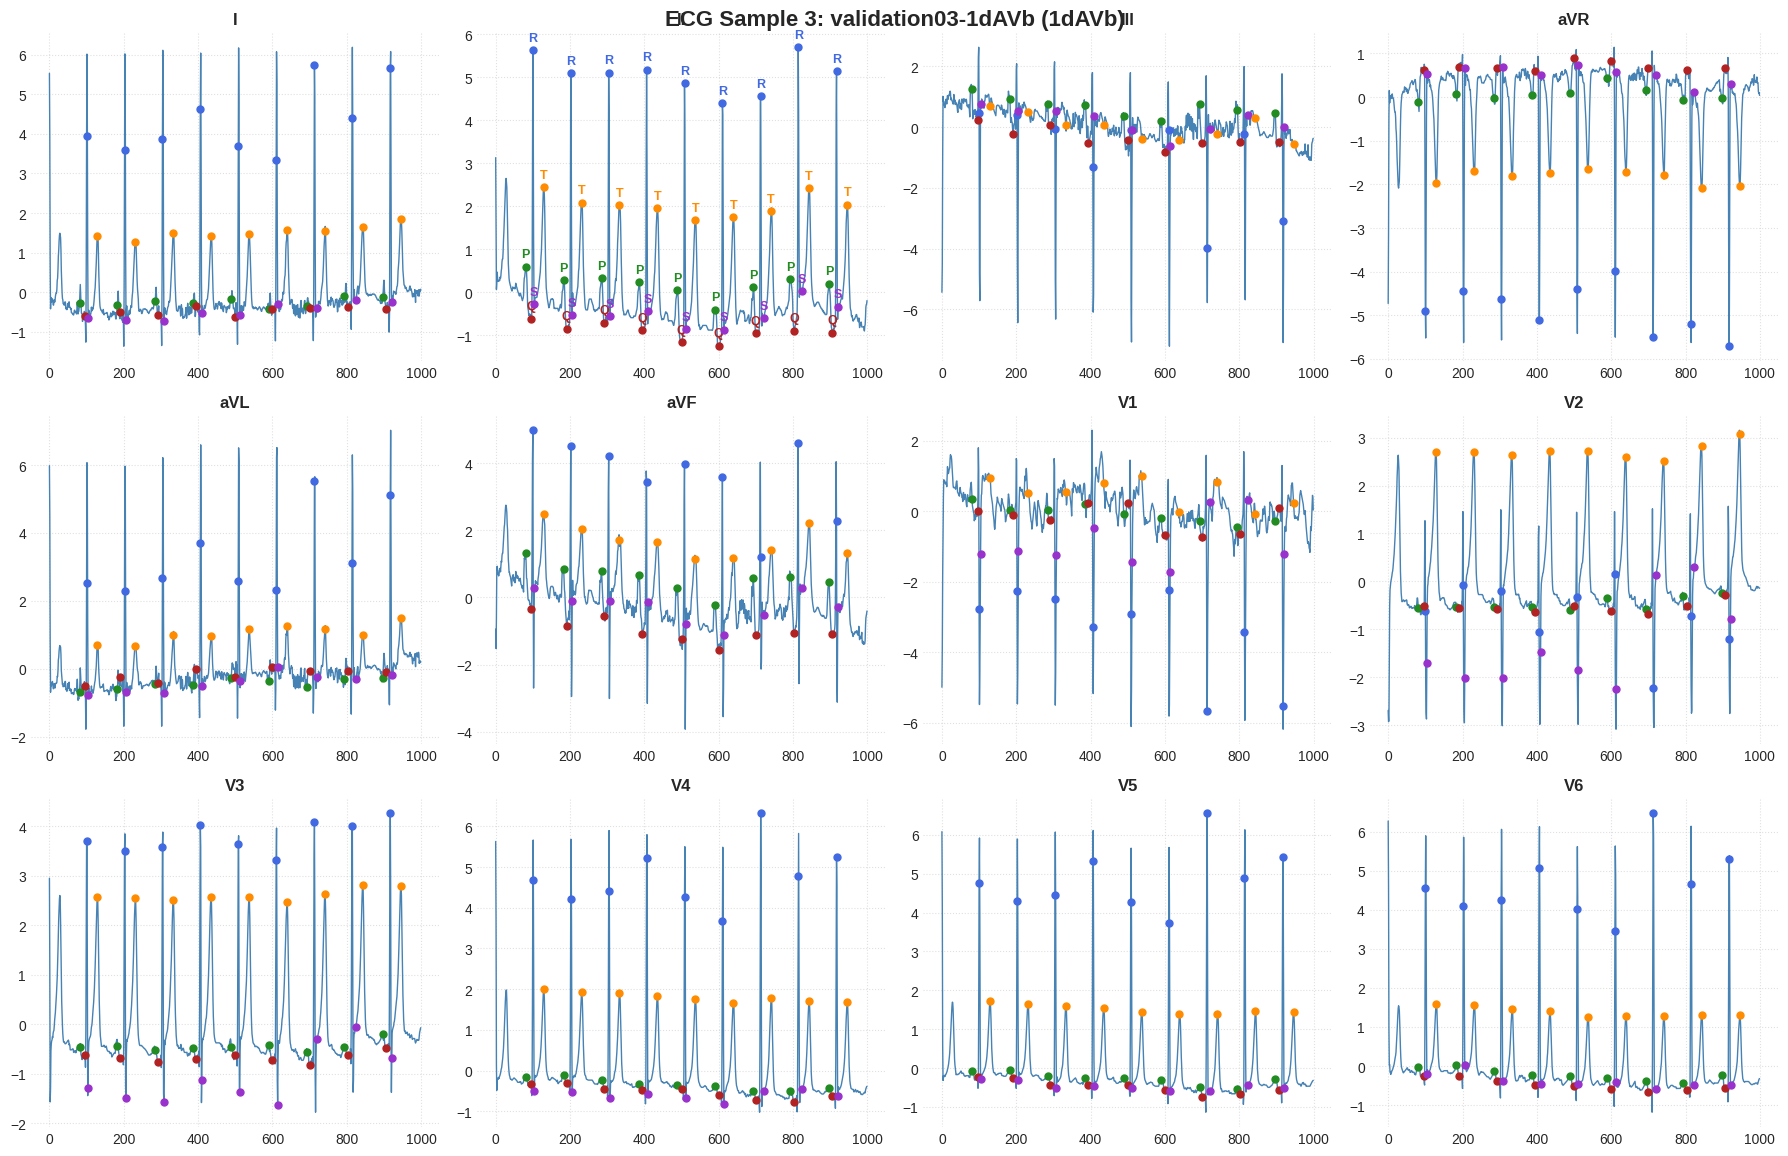

Saved figure with PQRST delineation to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/sample_ecg_validation_4.png


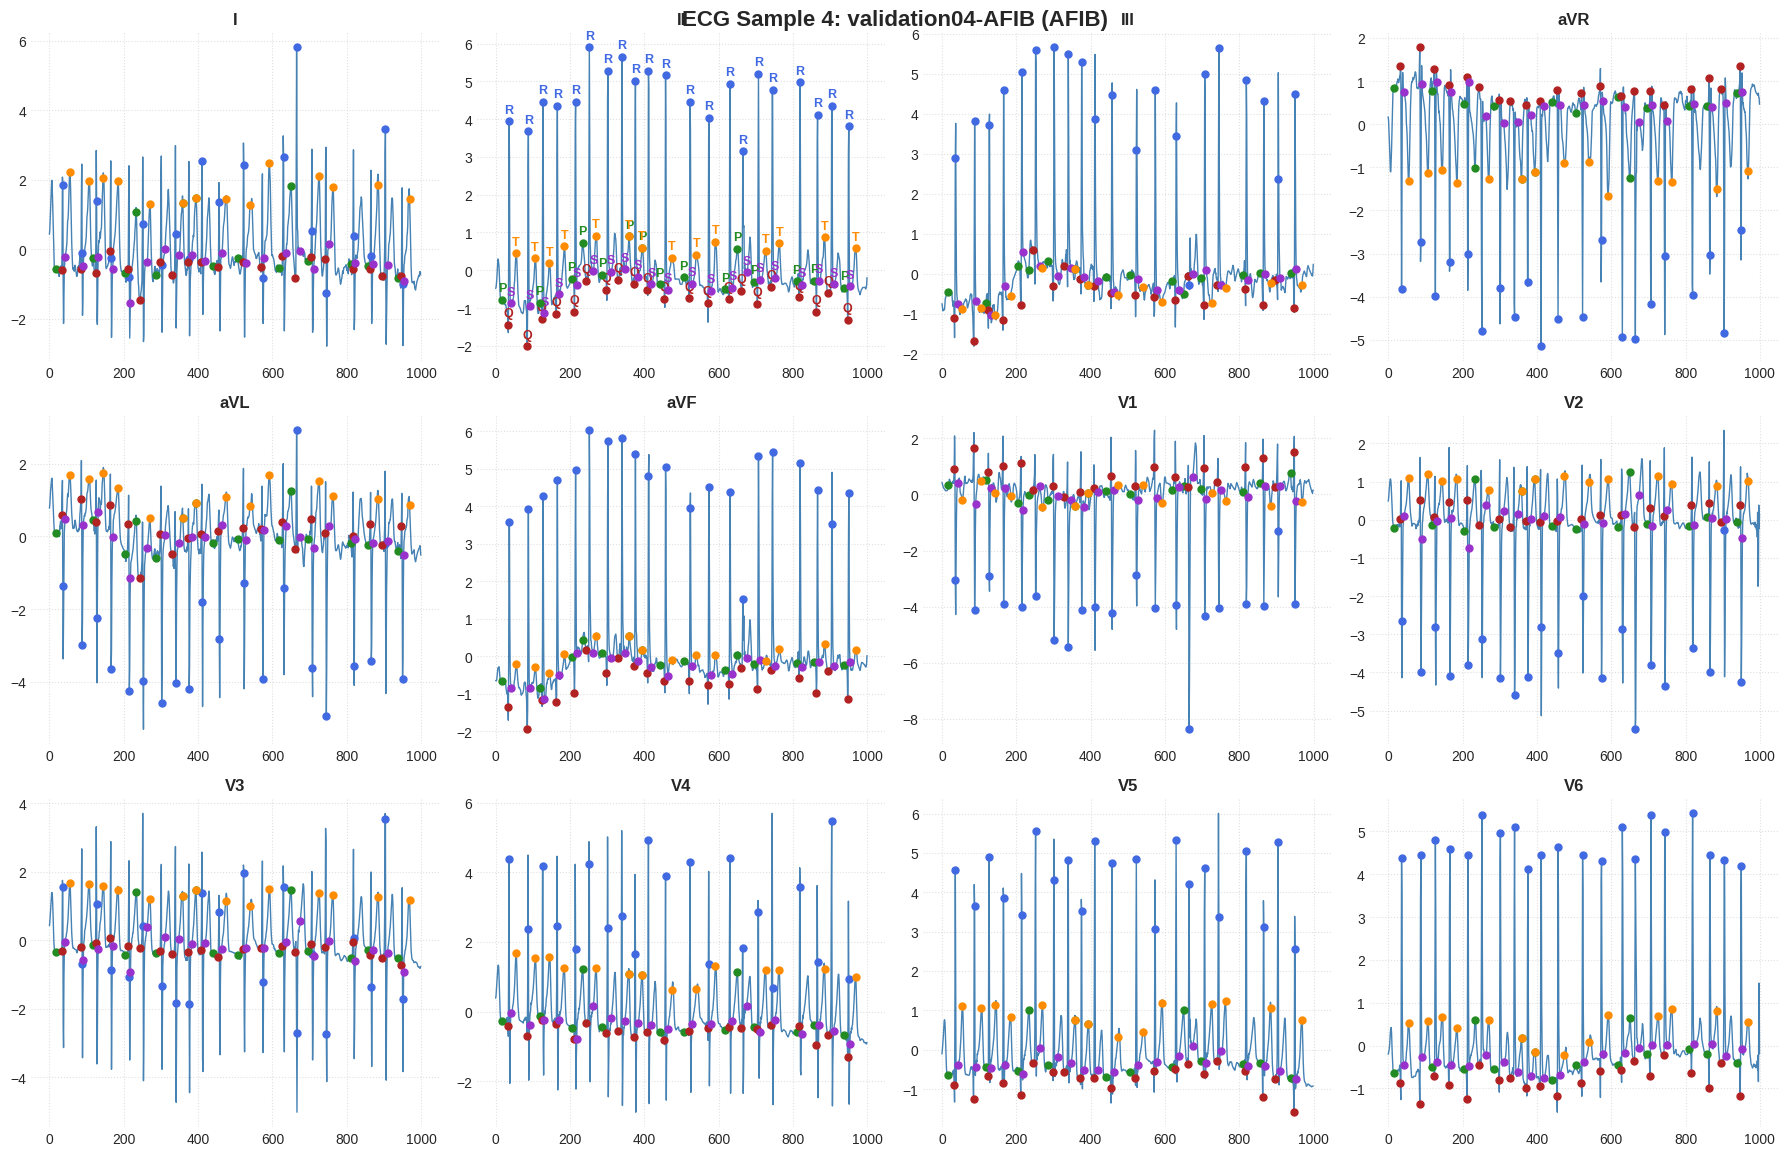

Saved figure with PQRST delineation to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/sample_ecg_validation_5.png


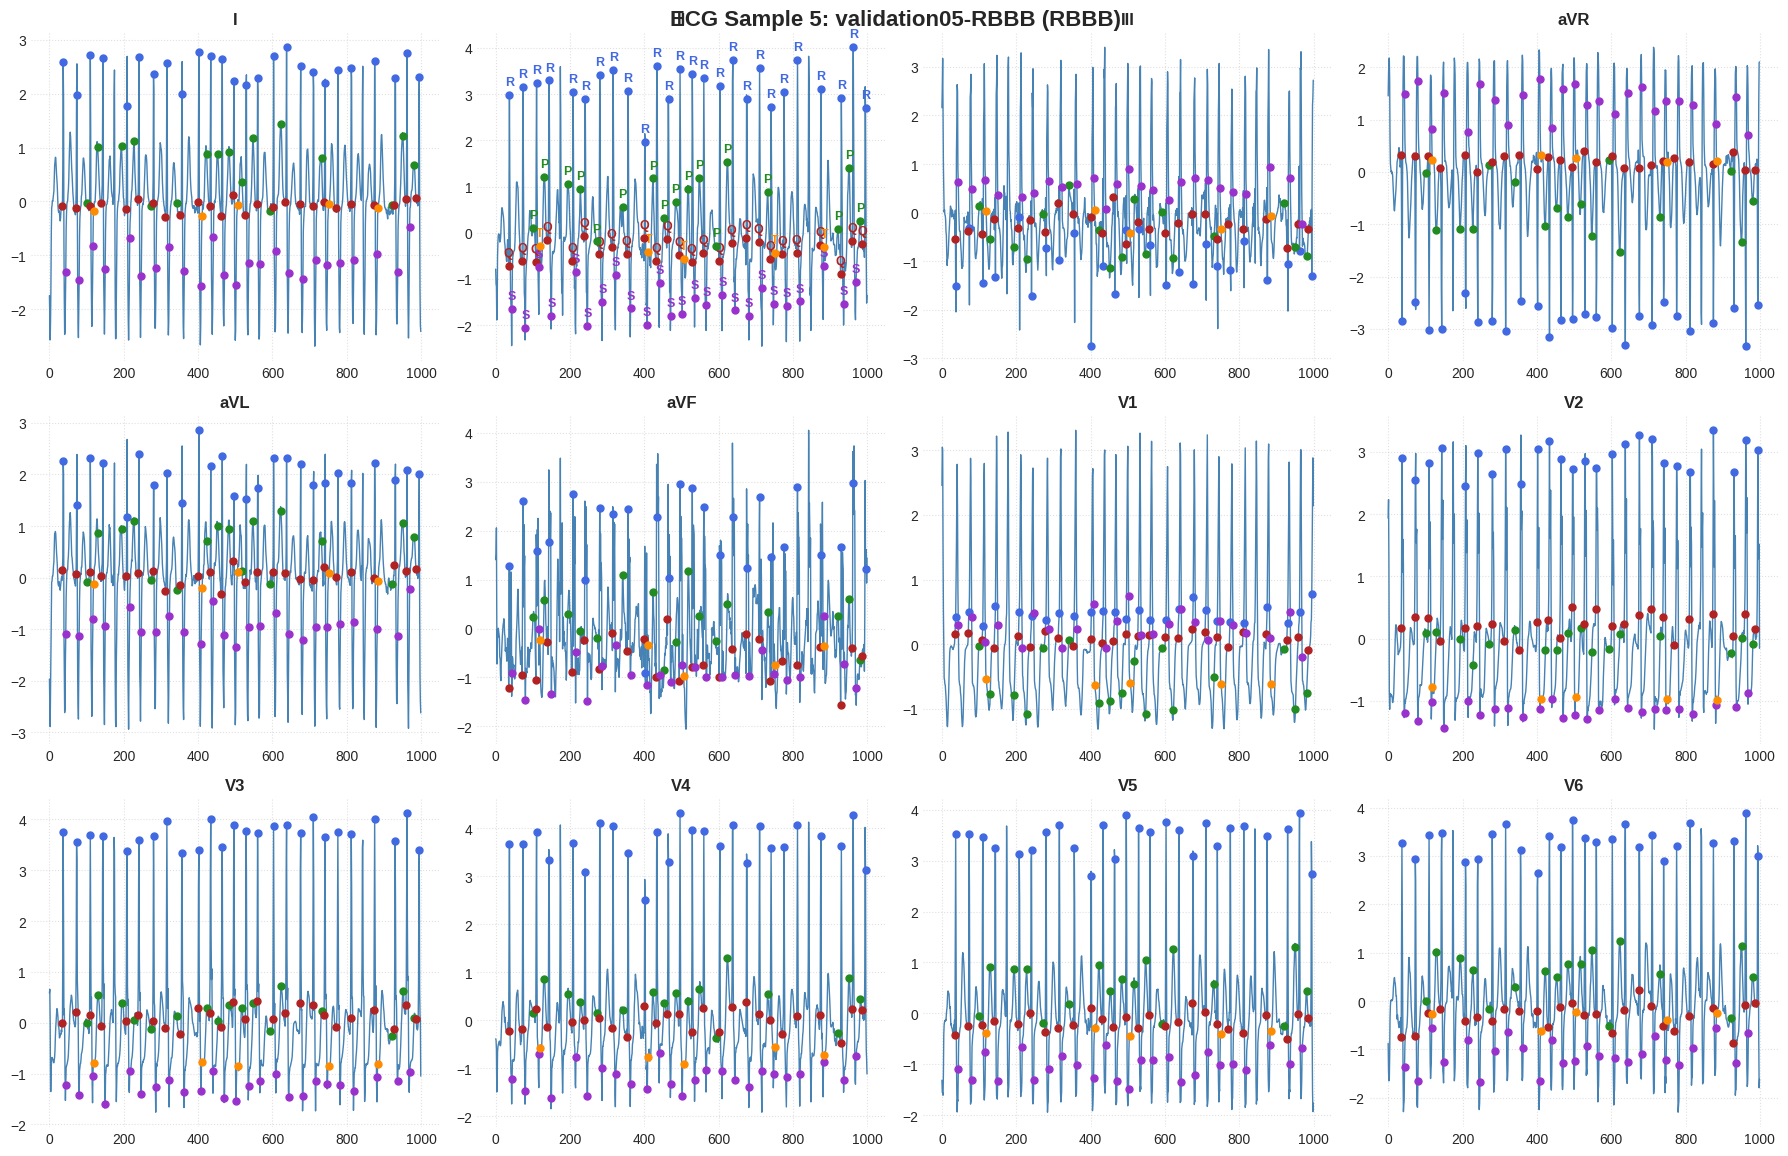

Saved figure with PQRST delineation to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/sample_ecg_validation_6.png


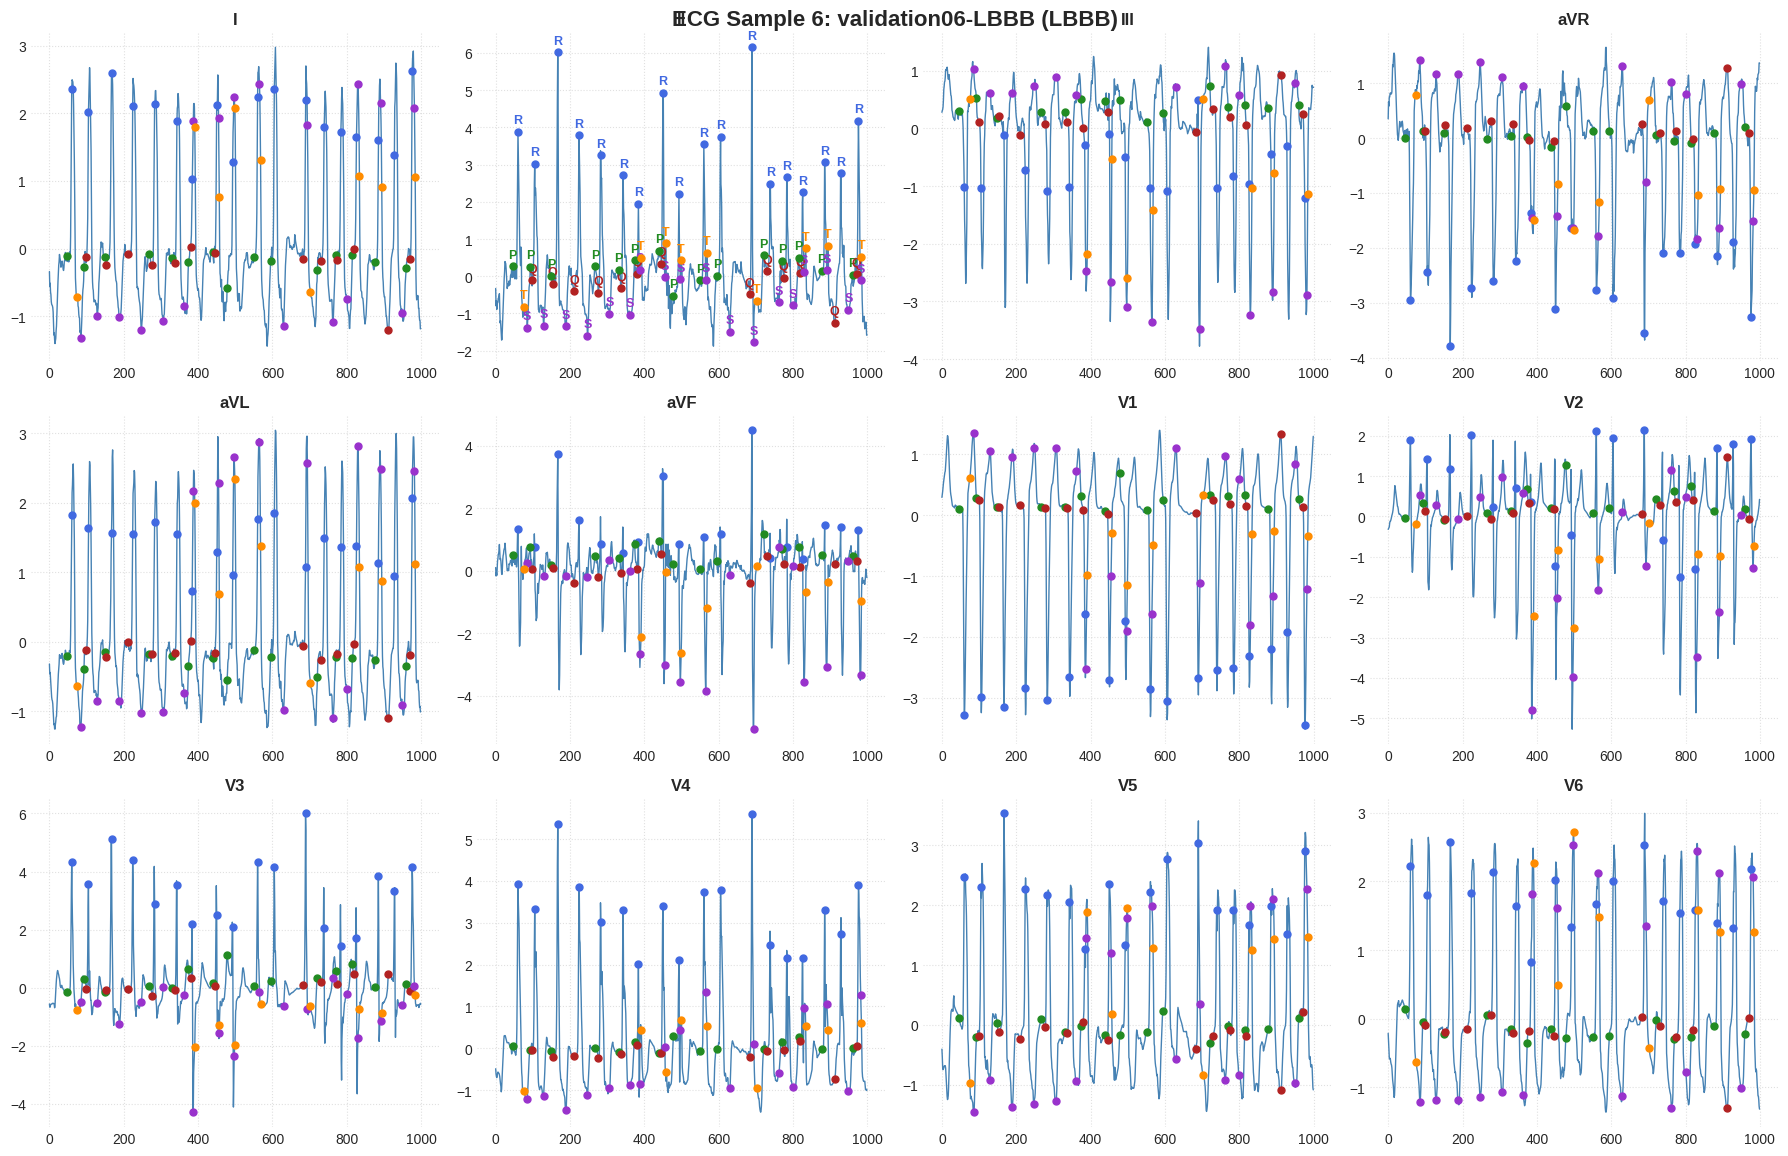

In [35]:
import numpy as np
import matplotlib.pyplot as plt
import neurokit2 as nk

# 1. Self-contained dataset loader fallback if not already executed in memory
if 'validation_dataset' not in locals() or validation_dataset is None:
    print("validation_dataset not found in memory. Attempting to load directly...")
    try:
        validation_dataset = LocalECGDataset(
            config.validation_dir,
            normalize=True,
            has_labels=True
        )
    except Exception as e:
        print(f"Error loading validation set: {e}")
        validation_dataset = None

def plot_ecg_sample_with_delineation(ecg_data, title, save_path=None):
    """
    Plots a 12-lead ECG sample with NeuroKit2 PQRST wave delineation.
    """
    leads = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
    
    # Clean Lead II (index 1) and detect R-peaks
    lead_ii_signal = ecg_data[1]
    lead_ii_cleaned = nk.ecg_clean(lead_ii_signal, sampling_rate=100)
    _, rpeaks_info = nk.ecg_peaks(lead_ii_cleaned, sampling_rate=100)
    r_peaks = rpeaks_info.get('ECG_R_Peaks', [])
    
    # Delineate other waves (P, Q, S, T) using NeuroKit2 DWT/peak methods
    waves = {}
    if len(r_peaks) > 0:
        try:
            # Discrete Wavelet Transform delineation
            _, waves = nk.ecg_delineate(lead_ii_cleaned, r_peaks, sampling_rate=100, method='dwt')
        except Exception:
            try:
                # Peak-based method fallback
                _, waves = nk.ecg_delineate(lead_ii_cleaned, r_peaks, sampling_rate=100, method='peak')
            except Exception as e:
                print(f"Warning: NeuroKit2 delineation failed: {e}")
                waves = {}
                
    # Create a 3x4 lead grid
    fig, axes = plt.subplots(3, 4, figsize=(18, 12))
    fig.suptitle(title, fontsize=16, fontweight='bold', y=0.96)
    
    # Peak colors
    colors = {
        'P': 'forestgreen',
        'Q': 'firebrick',
        'R': 'royalblue',
        'S': 'darkorchid',
        'T': 'darkorange'
    }
    
    # Plot each lead and overlay PQRST peaks
    for idx, lead in enumerate(leads):
        ax = axes[idx // 4, idx % 4]
        signal = ecg_data[idx]
        
        # Plot continuous ECG lead wave
        ax.plot(signal, linewidth=1.0, color='steelblue', label='ECG')
        ax.set_title(lead, fontsize=12, fontweight='bold')
        
        # Overlay detected peaks
        # R-peaks
        for r_val in r_peaks:
            if 0 <= r_val < len(signal):
                ax.scatter(r_val, signal[r_val], color=colors['R'], s=25, zorder=5)
                
        # Delineated P, Q, S, and T peaks
        for wave_key, label, color in [('ECG_P_Peaks', 'P', colors['P']),
                                       ('ECG_Q_Peaks', 'Q', colors['Q']),
                                       ('ECG_S_Peaks', 'S', colors['S']),
                                       ('ECG_T_Peaks', 'T', colors['T'])]:
            peak_indices = waves.get(wave_key, [])
            for p_val in peak_indices:
                if p_val is not None and not np.isnan(p_val):
                    p_val = int(p_val)
                    if 0 <= p_val < len(signal):
                        ax.scatter(p_val, signal[p_val], color=color, s=25, zorder=5)
                        
                        # Label text annotation only on Lead II to keep other leads clean
                        if lead == 'II':
                            ax.annotate(label, xy=(p_val, signal[p_val]), xytext=(p_val, signal[p_val] + 0.15),
                                        fontsize=9, fontweight='bold', color=color,
                                        ha='center', va='bottom')
                                        
        # Label R-peaks on Lead II specifically
        if lead == 'II':
            for r_val in r_peaks:
                if 0 <= r_val < len(signal):
                    ax.annotate('R', xy=(r_val, signal[r_val]), xytext=(r_val, signal[r_val] + 0.15),
                                fontsize=9, fontweight='bold', color=colors['R'],
                                ha='center', va='bottom')
                                
        ax.grid(True, linestyle=':', alpha=0.6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_visible(False)
        ax.spines['bottom'].set_visible(False)
        
    plt.tight_layout()
    
    # Save output to disk
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved figure with PQRST delineation to {save_path}")
        
    plt.show()

# Run the plotting loop
if validation_dataset:
    print(f"Generating and plotting {len(validation_dataset)} validation samples with NeuroKit2 wave peaks...")
    for i in range(len(validation_dataset)):
        sample = validation_dataset[i]
        
        # Execute the custom plotting function
        plot_ecg_sample_with_delineation(
            sample['ecg'].numpy(),
            title=f"ECG Sample {i+1}: {sample['filename']} ({sample['label_str']})",
            save_path=config.output_dir / f"sample_ecg_validation_{i+1}.png"
        )


---

## 10. CodeCarbon

This section generates total carbon emission for running this notebook.

In [36]:
# 2. Stop the notebook-level tracker and log the results
if 'notebook_tracker' in locals() and notebook_tracker is not None:
    notebook_tracker.__exit__(None, None, None)
    emissions = notebook_tracker.get_emissions()
    
    print("====================================================")
    print("🌱 Notebook Carbon Emissions Tracking Stopped!")
    if emissions is not None:
        print(f"Total Notebook Emissions: {emissions:.6f} kg CO2eq")
        print(f"Data saved to: {config.output_dir}/carbon_emissions_notebook.csv")
    else:
        print("Emissions tracked successfully. Refer to the output CSV file for raw metrics.")
    print("====================================================")
else:
    print("Warning: notebook_tracker was not initialized at the start of the session.")

🌱 Notebook Carbon Emissions Tracking Stopped!
Total Notebook Emissions: 0.020481 kg CO2eq
Data saved to: /home/21522611/Documents/AdvancedAIAssignment3Prac/output/carbon_emissions_notebook.csv
